# [이론] 문장 임베딩 — 단어가 달라도 가까운 글

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 왜 문장 임베딩이 필요한가

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 비정형 데이터(자연어)</div>
<h1 style="color:#000000;margin:10px 0">문장 임베딩 — 단어가 달라도 가까운 글</h1>
<div style="font-size:1.05em;color:#656565">단어가 하나도 겹치지 않아도 주제가 가까운 글을 문장 임베딩의 코사인으로 찾습니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

### 핵심 질문: 코사인 몇 이상을 같은 이야기로 볼 수 있는가 [필수]

쇼핑 리뷰 2건을 보겠습니다.

> 「배송이 정말 빨라요」
>
> 「택배가 하루 만에 도착했어요」

둘 다 배송이 빨랐다는 말이지만 겹치는 단어가 하나도 없습니다. **같은 이야기**는 주제와 주장이 모두 같은 두 글이고, 위 두 리뷰가 그 예입니다. 배송이 빨랐다는 글과 늦었다는 글은 주제가 같아도 주장이 반대라 같은 이야기가 아닙니다.

그런데 문서 비율을 배울 때 쓴 문서-단어 행렬로는 위 두 문장이 닮은 점이 없는 글입니다. 집단 비교에서 쓴 TF-IDF 로도 마찬가지입니다. 두 방법은 같은 단어가 있어야 두 글이 비슷하게 계산되기 때문입니다.

**단어가 달라도 가까운 글은 무엇으로 찾나요?**

새로 나오는 용어는 2개입니다.

- **문장 인코더(sentence encoder)**: 문장 하나를 수의 벡터 하나로 바꾸는, 미리 학습된 모델입니다.
- **문장 임베딩(sentence embedding)**: 문장 인코더가 만든 그 벡터입니다.

두 글의 문장 임베딩이 얼마나 가까운지는 코사인으로 나타냅니다. 코사인은 원점에서 뻗은 두 화살표의 방향이 얼마나 같은지 나타내는 값이고, −1 에서 1 사이입니다.

```text
−1 (정반대 방향, 180°) ──── 0 (직각, 90°) ──── 1 (같은 방향, 0°)
```

두 화살표 사이의 각이 작을수록 코사인은 1 에 가깝고, 각이 90° 면 0 입니다. 아래 그림에서 볼 것은 두 화살표 사이의 각 하나입니다. 각이 80° 로 직각에 가까워 코사인은 0.17 입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/2/23/CosineSimilarity.png" alt="원점에서 뻗은 노란 화살표 두 개(car 쪽과 truck 쪽) 사이에 80° 라고 적힌 파란 호가 있고, 그 밖에 convertible · Chevrolet · Ford · towing 같은 단어 점이 흩어진 그림" width="560" height="283"/>
<p align="center"><em>▲ car 와 truck 쪽으로 뻗은 두 화살표 사이의 각이 80° 다. 직각에 가까워 코사인은 cos 80° ≈ 0.17 이다 (출처: Wikimedia Commons, StandingFuture, CC BY-SA 4.0)</em></p>

그런데 주장이 반대인 두 글도 주제가 같으면 코사인이 클 수 있습니다. 그래서 코사인이 몇 이상이어야 같은 이야기인지는 정해져 있지 않습니다.

> 문장 인코더로 바꾼 두 글의 코사인이 몇 이상이면, 두 글을 같은 이야기로 볼 수 있는가?

결론부터 말하면 세 가지입니다.

- 단어가 겹치지 않아도 주제가 가까운 글은 문장 임베딩의 코사인으로 찾습니다. 같은 주장인지는 원문을 읽어 확인합니다. 별점은 단서입니다.
- 아무 리뷰 두 건의 코사인이 한 모델에서는 0.86 쯤, 다른 모델에서는 0.5 쯤 나옵니다. 그래서 같은 0.8 도 모델에 따라 뜻이 다릅니다.
- 몇 이상이라는 기준(임계값)은 쓰는 모델에서 사람이 원문을 읽어 확인한 쌍으로 정합니다. 모델 이름 없이 임계값만으로는 그 값을 해석할 수 없습니다.

**두 문장은 실제로 얼마나 가까운가요?**

이 수업은 문장 인코더 2개를 씁니다.

- KURE-v1 은 다국어 모델을 한국어 글로 더 학습한 모델입니다.
- multilingual-e5-small(줄여서 e5-small)은 여러 언어를 함께 학습한 모델입니다.

두 문장의 코사인은 문서-단어 행렬에서 0 이지만, KURE-v1 에서는 0.761 입니다.

**0.761 은 큰 값인가요?**

수 하나만으로는 알 수 없고, 같은 모델로 구한 다른 리뷰 쌍의 코사인과 비교해야 합니다. 비교할 리뷰는 집단 비교에서 쓴 리뷰 표본 2만 건의 앞 3,000건입니다.

```text
리뷰 3,000건 → 쌍 4,498,500개 (3,000 × 2,999 ÷ 2, 약 450만)
```

아래 그림은 모델마다 리뷰 쌍 약 450만 개의 코사인 분포이고, 하늘색 점이 두 문장의 코사인입니다.

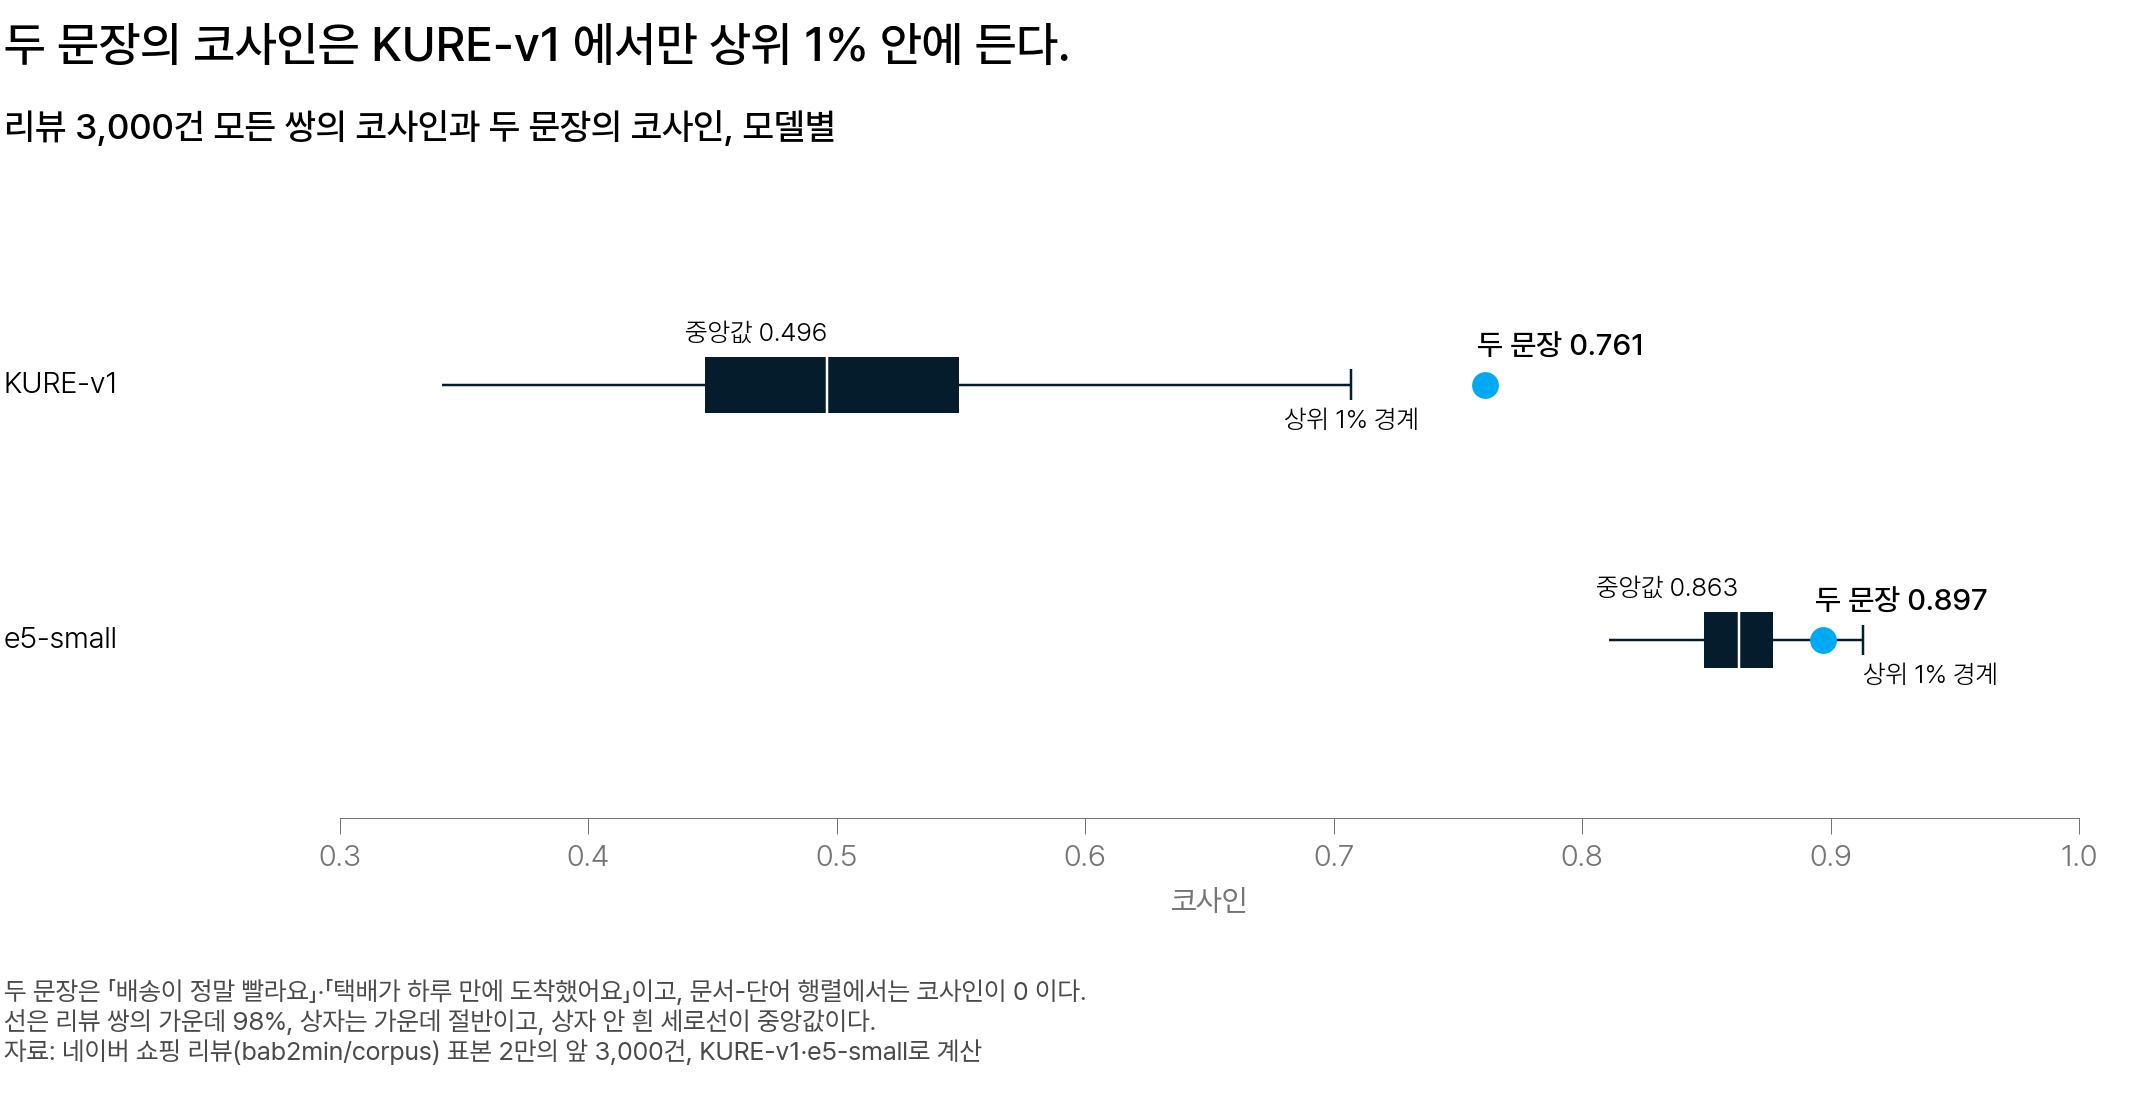

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 코사인이다. 위 줄이 KURE-v1, 아래 줄이 e5-small 이다. 선은 리뷰 쌍의 가운데 98%, 상자는 가운데 절반, 상자 안 흰 세로선은 중앙값이다. 선의 오른쪽 끝이 상위 1% 경계다. 하늘색 점이 두 문장의 코사인이고, KURE-v1 에서만 점이 상위 1% 경계 오른쪽에 있다</em></p>

| 문장 인코더 | 두 문장의 코사인 | 모든 쌍 코사인의 중앙값 | 두 문장보다 가까운 쌍 |
|---|---:|---:|---:|
| KURE-v1 | 0.761 | 0.496 | 1% 미만 |
| e5-small | 0.897 | 0.863 | 약 5% |

KURE-v1 에서 두 문장보다 가까운 쌍은 100쌍에 1쌍도 안 됩니다. 아무 리뷰 두 건이 이만큼 가까운 경우는 드물어서, 두 문장이 가깝다는 근거로 볼 수 있습니다.

e5-small 의 0.897 은 모든 쌍의 95% 가 그 아래인 값이라, 더 가까운 쌍이 약 5% 입니다. 값은 KURE-v1 의 0.761 보다 크지만, 더 가까운 쌍은 KURE-v1(1% 미만)보다 많습니다.

> 코사인이 큰지는 수 자체가 아니라 같은 모델의 모든 쌍 가운데 어디쯤인지로 판단합니다.

<div class="lms-summary">

**정리**

단어가 하나도 겹치지 않는 두 글도 문장 임베딩의 코사인은 클 수 있습니다. 그 값이 큰지는 같은 모델로 구한 모든 쌍의 코사인과 비교해 판단합니다.

코사인이 커도 주장이 반대인 두 글일 수 있습니다. 같은 이야기인지는 원문을 읽어 확인합니다.

</div>

## 1. 문장 임베딩이란 무엇인가

단어가 달라도 가까운 벡터는 어떻게 만들 수 있을까요?

### 코사인 유사도 [필수]

핵심 질문의 배송 두 문장이 얼마나 가까운지 수로 나타내려면, 두 벡터를 비교하는 식이 필요합니다.

**한 줄로 말하면 무엇인가요?**

**코사인 유사도(cosine similarity)** 는 두 벡터의 방향이 얼마나 같은지 나타내는 값입니다. 줄여서 코사인이라고 하고, 내적을 두 길이의 곱으로 나눠 구합니다.

$$
\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}
$$

- **내적(dot product)** $\mathbf{a}\cdot\mathbf{b}$: 원소끼리 곱해 모두 더한 값입니다. $a_1 b_1 + a_2 b_2 + \cdots + a_n b_n$ 입니다.
- **길이** $\lVert\mathbf{a}\rVert$: 원소 제곱합의 제곱근입니다. $\sqrt{a_1^2 + a_2^2 + \cdots + a_n^2}$ 입니다.
- $a_k$, $b_k$: 두 벡터의 $k$ 번째 원소입니다. 문서-단어 행렬이면 단어 $k$ 의 값입니다.
- $n$: 원소 수입니다.

**왜 두 길이의 곱으로 나누나요?**

- 내적은 방향이 같을수록 크지만 벡터가 길어도 커집니다. (1, 0) 끼리의 내적은 1 인데, 한쪽을 두 배 늘린 (2, 0) 으로 바꾸면 2 입니다.
- 두 길이의 곱으로 나누면 길이 차이가 없어지고 방향만 남습니다. (1, 0) 과 (2, 0) 은 2 ÷ (1 × 2) = 1 입니다.

**거리 대신 코사인을 쓰는 이유는 무엇인가요?**

필수 머신러닝 과목의 k-최근접 이웃(KNN)은 거리로 가까운 점을 골랐습니다. 그런데 같은 리뷰를 두 번 이어 쓴 글은 단어 횟수가 모두 두 배라, 내용은 같아도 벡터의 길이가 다릅니다.

| | 거리 | 코사인 |
|---|---|---|
| 묻는 것 | 두 점이 얼마나 떨어져 있는가 | 두 화살표의 방향이 얼마나 같은가 |
| 원래 글과 두 번 이어 쓴 글 | 원래 글 벡터의 길이(‖a‖)만큼 떨어짐 | 방향이 같아 1 |

따라서 글을 비교할 때는 길이 차이를 없앤 코사인을 씁니다. 아래 그림의 세 벡터로 먼저 계산해 봅니다.

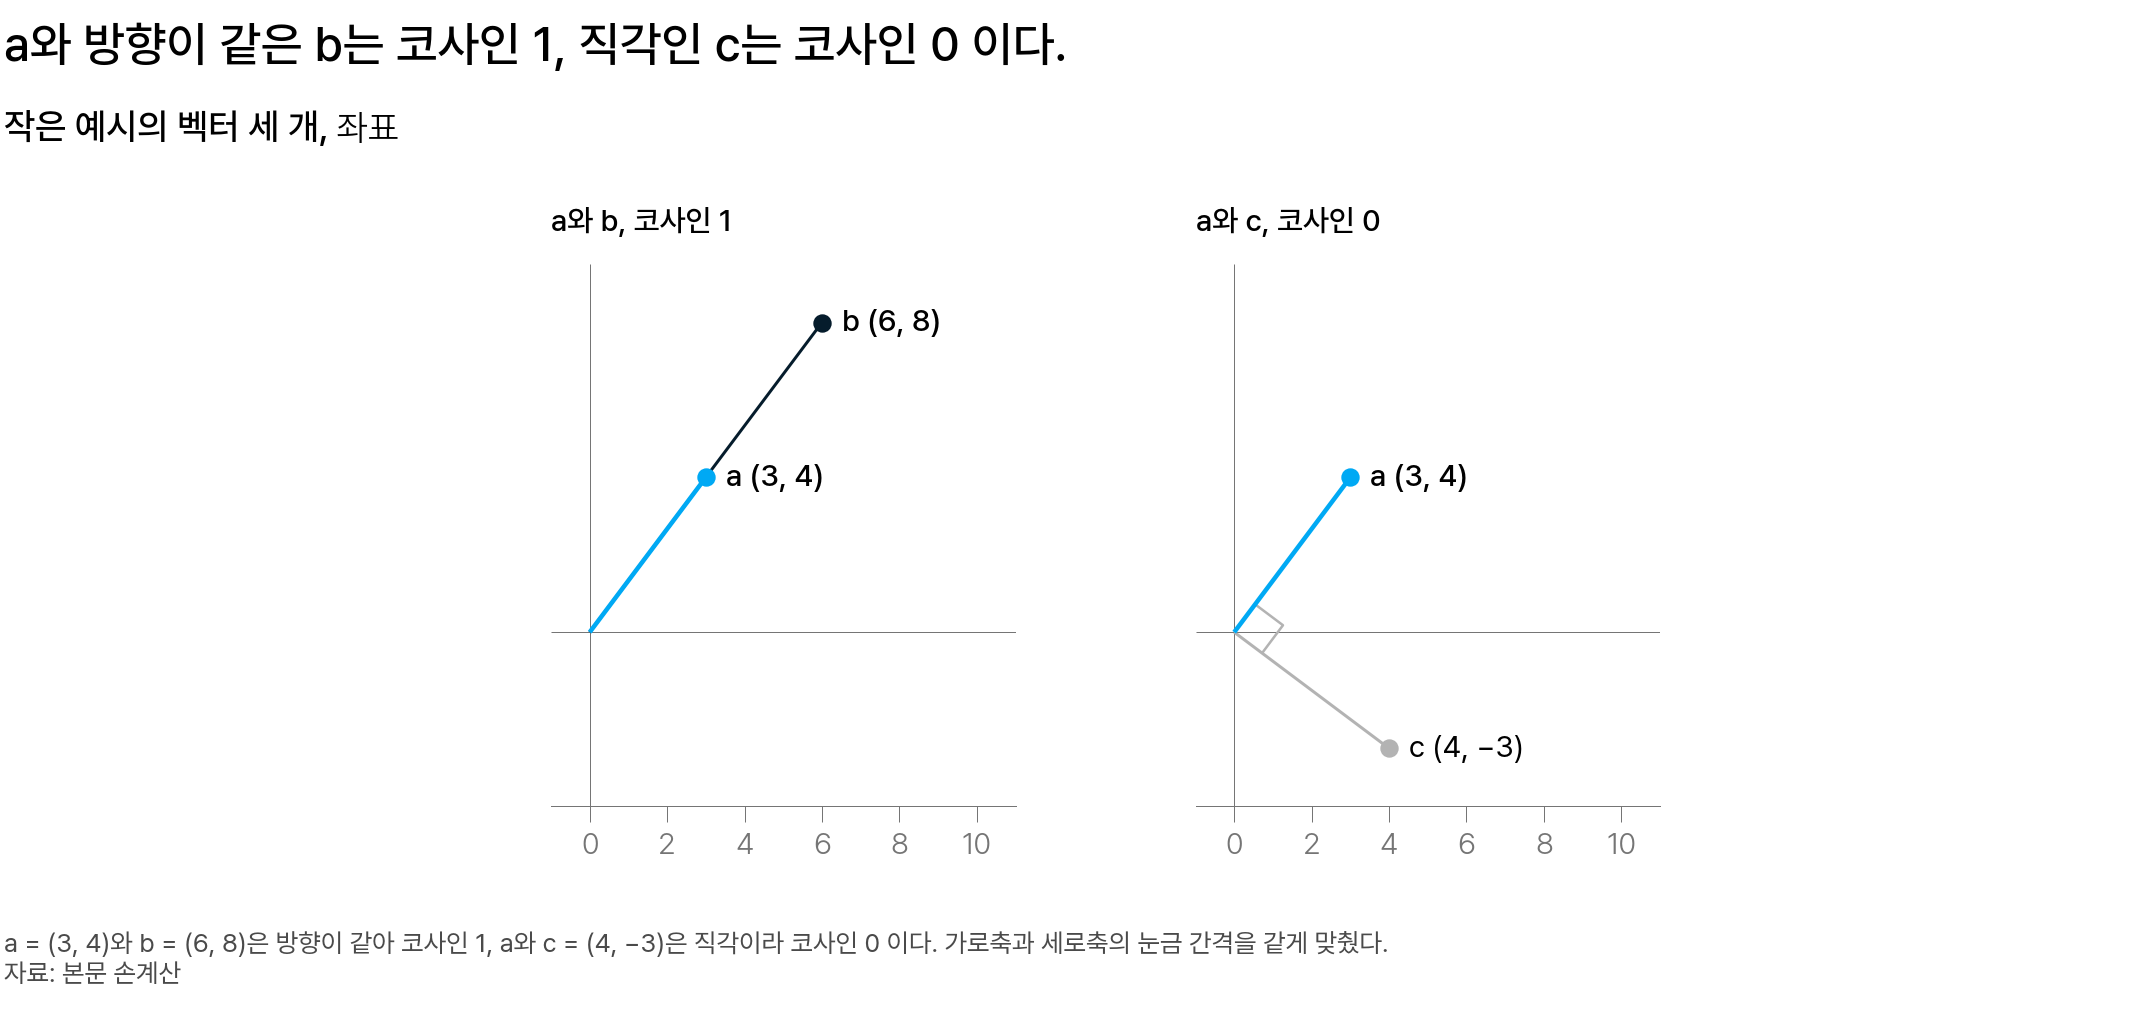

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 작은 예시의 벡터 3개. 가로축이 첫째 수, 세로축이 둘째 수다. 왼쪽은 a(하늘색)와 b(남색), 오른쪽은 a 와 c(회색)다</em></p>

세 벡터 a, b, c 를 식에 대입해 봅니다.

| 두 벡터 | 내적 | 두 길이의 곱 | 코사인 |
|---|---|---|---:|
| a = (3, 4), b = (6, 8) | $3 \times 6 + 4 \times 8 = 50$ | $5 \times 10 = 50$ | 1 |
| a = (3, 4), c = (4, −3) | $3 \times 4 + 4 \times (-3) = 0$ | $5 \times 5 = 25$ | 0 |

- b 는 a 를 두 배로 늘린 벡터라 길이는 두 배이지만 코사인은 1 입니다.
- c 는 a 와 직각이라 내적이 0 이고 코사인도 0 입니다.

**단어가 하나도 겹치지 않으면 코사인은 얼마인가요?**

핵심 질문의 배송 두 문장에서 명사만 남기면 「배송」 대 「택배 · 하루 · 도착」이라 겹치는 단어가 없습니다.

이처럼 겹치는 단어가 없을 때 코사인이 얼마인지, 집단 비교에서 계산한 예시 문서 3개의 TF-IDF 로 확인합니다. 문서 1 은 「배송 빠름 만족」, 문서 2 는 「배송 늦음 환불」, 문서 3 은 「환불 요청 환불」입니다.

| 두 문서 | 겹치는 단어 | 코사인 |
|---|---|---:|
| 문서 1 · 문서 2 | 배송 | 0.245 |
| 문서 1 · 문서 3 | 없음 | 0 |
| 문서 2 · 문서 3 | 환불 | 0.433 |

문서 1 에 나온 단어(만족 · 배송 · 빠름)는 문서 3 에서 값이 모두 0 입니다. 그래서 원소끼리 곱이 모두 0 이고 내적도 0 입니다. 내적이 0 이면 분모가 얼마든 코사인은 0 입니다.

<details class="lms-extra"><summary>자세히 — 예시 문서 3개의 TF-IDF 값</summary>

| 문서 | 늦음 | 만족 | 배송 | 빠름 | 요청 | 환불 |
|---|---:|---:|---:|---:|---:|---:|
| 1 「배송 빠름 만족」 | 0 | 0.623 | 0.474 | 0.623 | 0 | 0 |
| 2 「배송 늦음 환불」 | 0.681 | 0 | 0.518 | 0 | 0 | 0.518 |
| 3 「환불 요청 환불」 | 0 | 0 | 0 | 0 | 0.549 | 0.836 |

문서마다 길이가 1 이라, 같은 단어의 값끼리 곱해 더한 내적이 곧 위 코사인입니다. 문서 1 · 문서 2 는 「배송」만 겹쳐 0.474 × 0.518 ≈ 0.245 입니다.

</details>

> 단어가 하나도 겹치지 않는 두 글은 문서-단어 행렬과 TF-IDF 에서 코사인이 늘 0 입니다.

**길이를 1 로 맞추면 코사인 식에서 무엇이 빠지나요?**

길이를 1 로 맞추려면 벡터를 그 길이로 나눕니다. 방향은 바뀌지 않고 길이만 1 이 됩니다. 집단 비교에서 본 L2 정규화도 벡터를 길이로 나누는 계산이라, 위 TF-IDF 예시도 문서마다 길이가 1 입니다. 두 벡터의 길이가 모두 1 이면 분모가 1 × 1 = 1 이라 내적이 곧 코사인입니다.

이 수업의 두 문장 인코더도 문장 임베딩의 길이를 1 로 맞춥니다. 아래 코드는 a · b · c 의 코사인을 구한 뒤, a 와 b 를 길이 1 로 맞춰 내적을 구합니다.

In [ ]:
# 코사인 = 내적 ÷ 두 길이의 곱, 그리고 길이 1 로 맞춘 벡터끼리의 내적
import numpy as np

a = np.array([3.0, 4.0])
b = np.array([6.0, 8.0])            # a 를 두 배로 늘린 벡터. 세 배로 바꿔 다시 실행해 본다
c = np.array([4.0, -3.0])


def cos(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))


print("cos(a, b) =", round(cos(a, b), 3))
print("cos(a, c) =", round(cos(a, c), 3))
a1, b1 = a / np.linalg.norm(a), b / np.linalg.norm(b)
print("a 를 길이 1 로 =", a1.round(3), "· 길이 1 끼리의 내적 =", round(float(a1 @ b1), 3))

출력의 「a 를 길이 1 로」 값 (0.6, 0.8) 은 아래 계산에서 나옵니다.

```text
a ÷ 5  = (3, 4) ÷ 5  = (0.6, 0.8)
b ÷ 10 = (6, 8) ÷ 10 = (0.6, 0.8)
두 벡터의 내적 = 0.6 × 0.6 + 0.8 × 0.8 = 0.36 + 0.64 = 1.0
```

- a 와 b 는 방향이 같아, 길이 1 로 맞추면 같은 벡터가 됩니다.
- 길이 1 끼리의 내적 1.0 은 cos(a, b) = 1.0 과 같습니다. b 를 a 의 세 배로 바꿔 다시 실행해도 두 값은 1.0 그대로입니다.

길이를 1 로 맞춘 벡터끼리는 **내적이 곧 코사인**입니다. 그래서 리뷰가 수천 건이어도 길이로 나누는 계산 없이 내적만 구하면 됩니다.

### 문장 임베딩의 수는 어떻게 글의 뜻을 나타내는가 [필수]

문서-단어 행렬의 열에는 단어 이름이 있습니다. 「환불」 열의 값 2 는 그 글에 「환불」이 두 번 나왔다는 뜻입니다.

**문장 임베딩의 수 하나는 무엇을 뜻하나요?**

리뷰 「배송이 좀 느려요～」를 문장 임베딩으로 바꿔 봅니다. 수가 e5-small 에서는 384개, KURE-v1 에서는 1,024개 나옵니다.

```text
e5-small 의 문장 임베딩 = (0.0182, −0.0125, −0.0717, … 수 384개)
```

그런데 첫째 수 0.0182 가 무엇의 점수인지는 정해져 있지 않습니다. 좌표 하나하나에 이름이 없기 때문입니다.

**한 줄로 말하면 무엇인가요?**

문장 임베딩은 문장 인코더가 글 하나를 바꾼 벡터이고, 그 수 하나하나에는 정해진 뜻이 없습니다.

**좌표에 이름이 있으면 어떻게 되나요?**

리뷰마다 사람이 가격 만족과 배송 만족 두 기준으로 점수를 매긴다고 하겠습니다. 리뷰는 예로 만들었습니다.

| 리뷰 | 본문 | 가격 만족 | 배송 만족 |
|---|---|---:|---:|
| A | 값이 싸서 좋고 배송도 무난해요 | 4 | 3 |
| B | 택배가 금방 왔어요 가격도 적당하네요 | 3 | 4 |
| C | 너무 비싸요 대신 빨리 받았어요 | −3 | 4 |

세 벡터의 길이는 모두 $\sqrt{4^2 + 3^2} = 5$ 입니다. 이 길이로 A 와 B, A 와 C 의 코사인을 구합니다.

$$
\cos(A, B) = \frac{4 \times 3 + 3 \times 4}{5 \times 5} = \frac{24}{25} = 0.96
$$

$$
\cos(A, C) = \frac{4 \times (-3) + 3 \times 4}{5 \times 5} = \frac{0}{25} = 0
$$

- A 와 B 는 명사와 용언이 하나도 겹치지 않아 문서-단어 행렬로는 코사인이 0 입니다. 하지만 두 기준의 점수가 비슷해 0.96 으로 가깝습니다.
- C 는 가격 만족의 부호가 A 와 반대라, 두 곱 −12 와 12 를 더하면 0 이 됩니다. 사람이 매긴 만족 점수라 주장(만족인지 불만인지)이 좌표에 그대로 반영된 경우입니다.

**세 벡터를 회전하면 무엇이 달라지나요?**

같은 세 벡터를 원점을 중심으로 90° 회전합니다.

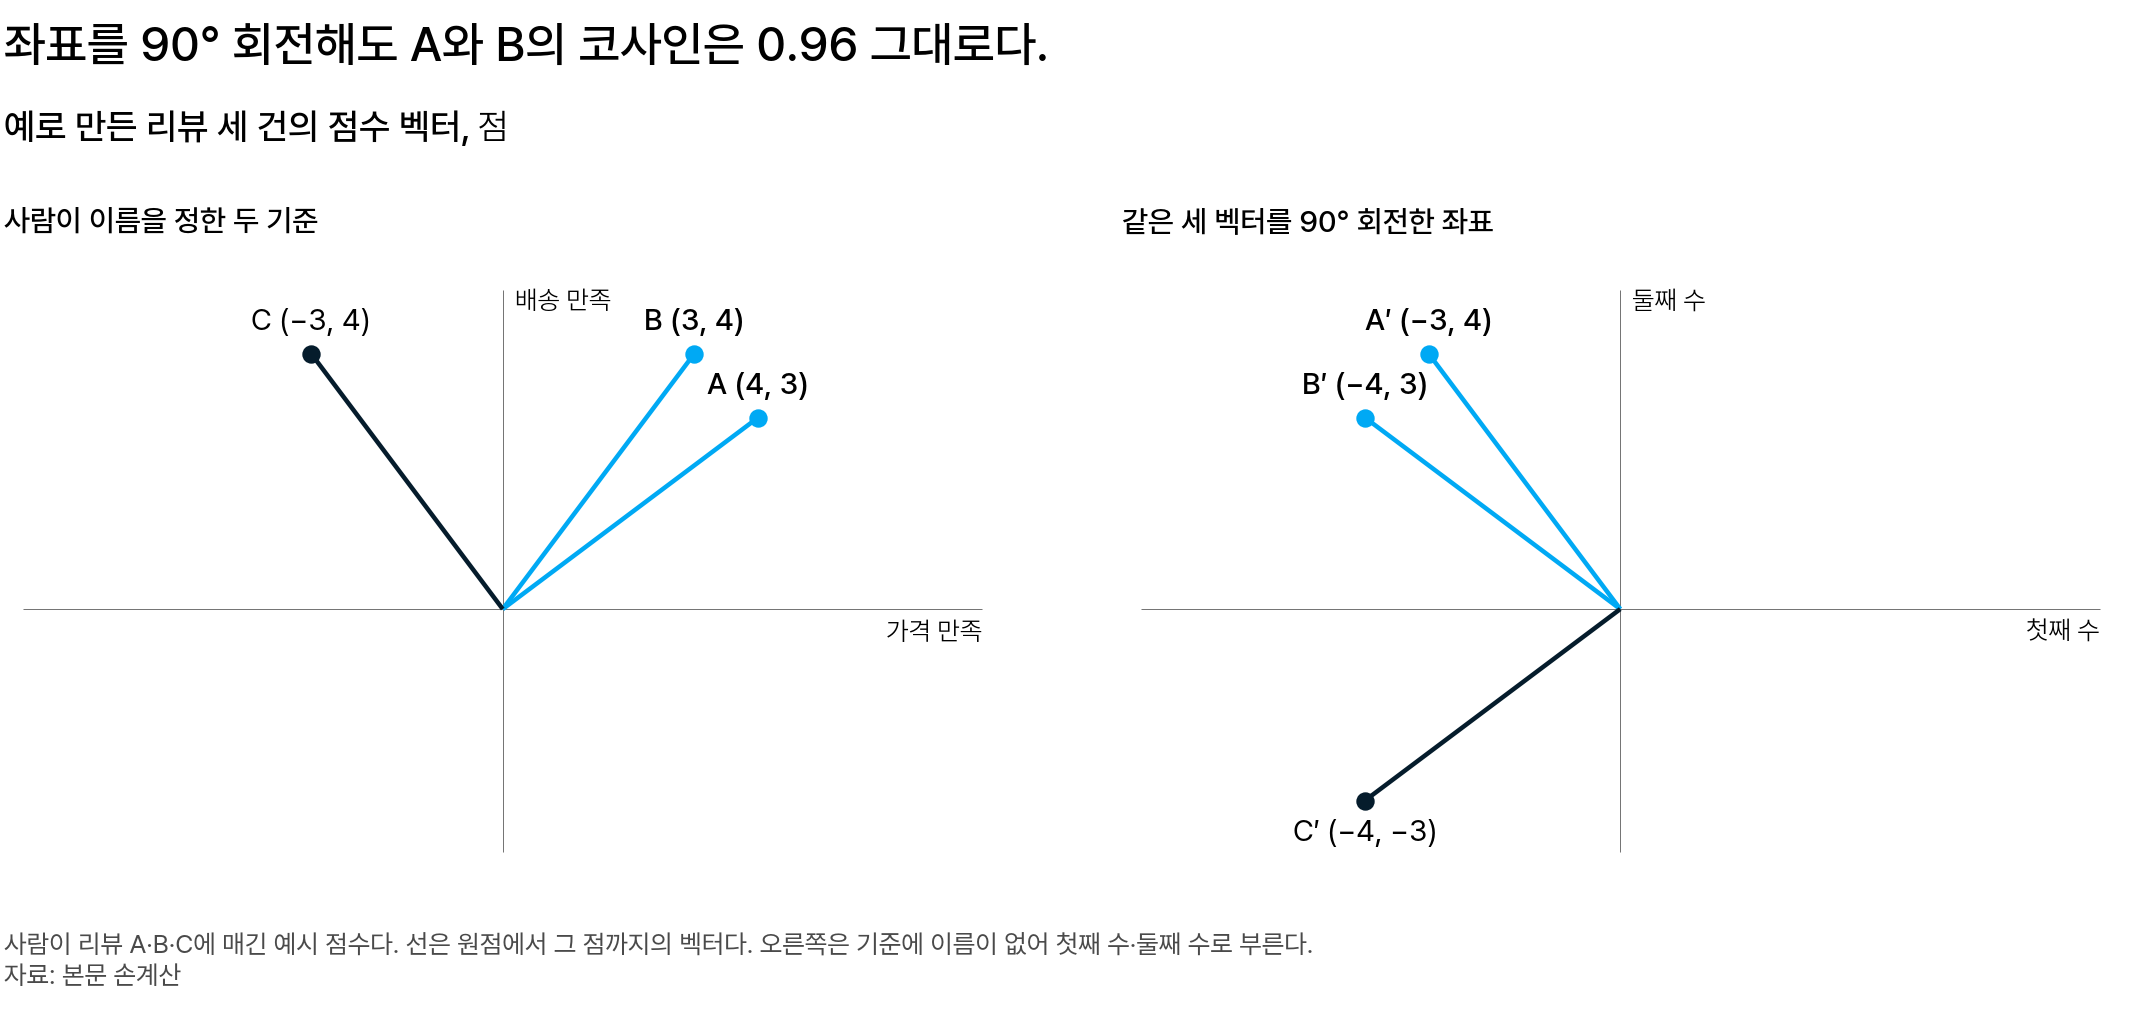

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 왼쪽은 사람이 이름을 정한 두 기준, 오른쪽은 같은 세 벡터를 90° 회전한 좌표다. A·B 는 하늘색이다</em></p>

회전한 뒤에 A 는 (−3, 4), B 는 (−4, 3) 이 됩니다. 두 벡터 사이의 각은 그대로라 코사인도 0.96 그대로입니다.

그런데 회전한 A (−3, 4) 는 회전 전 C 와 같은 수입니다. 첫째 수만으로는 가격에 만족한 A 와 비싸다고 한 C 를 구별할 수 없습니다. 코사인은 그대로인데, 첫째 수가 가격 만족이라는 뜻은 사라졌습니다.

**문장 인코더는 무엇을 목표로 학습하나요?**

**대조 학습(contrastive learning)** 은 관련된 두 글은 코사인이 높게, 관련 없는 두 글은 낮게 나오게 하는 학습입니다.

관련된 두 글은 같은 뜻의 두 문장, 질문과 그 답 같은 쌍입니다. 문장 인코더는 이런 쌍으로 대조 학습을 합니다.

학습에 쓰지 않은 두 문장도 가까워집니다. 같은 단어가 여러 학습 쌍에 거듭 나오기 때문입니다. 예를 들어 같은 뜻의 학습 쌍 여럿에서 한쪽은 「배송」, 다른 쪽은 「택배」를 썼다고 하겠습니다.

```text
같은 뜻의 학습 쌍 여럿 (한쪽은 「배송」, 다른 쪽은 「택배」)
   ↓ 쌍마다 코사인을 높이도록 학습
「배송」을 쓴 글과 「택배」를 쓴 글의 벡터가 비슷한 방향이 됨
   ↓ 학습이 끝난 인코더에 새 문장을 넣음
학습 쌍에 없던 핵심 질문의 배송 두 문장도 리뷰 쌍 대부분보다 가까움
```

**좌표 하나에 이름을 정할 수 없는 이유는 무엇인가요?**

대조 학습은 쌍의 코사인만 맞춥니다. 회전해도 코사인이 같아, 첫째 수가 가격 만족을 뜻하도록 학습할 이유가 없습니다. 그래서 학습이 끝난 인코더의 좌표가 어느 쪽으로 회전해 있는지 정해져 있지 않고, 좌표 하나에 이름을 정할 수 없습니다.

> 문장 임베딩은 좌표 하나의 값을 해석하지 않고 두 벡터의 코사인으로 씁니다.

<details class="lms-extra"><summary>더 깊이 — 사람이 이름을 정한 좌표의 예</summary>

사람이 두 기준에 이름을 정하면 점의 위치를 해석할 수 있습니다.

<img src="https://developers.google.com/static/machine-learning/crash-course/images/embeddings_2D.png" alt="음식 6개를 샌드위치다움과 디저트다움 두 기준의 점수로 나타낸 그림" width="640" height="388" />
<p align="center"><em>▲ 음식 6개를 가로축 샌드위치다움(sandwichness), 세로축 디저트다움(dessertness)의 점수로 나타낸 그림. 사람이 이름을 정한 기준이라 위치가 무엇을 뜻하는지 알 수 있다 (출처: Google Machine Learning Crash Course, Embeddings, CC BY 4.0)</em></p>

다만 이 그림의 출처인 Google 강좌도 실제 임베딩의 좌표가 디저트다움처럼 뜻이 분명한 경우는 드물다고 설명합니다.

</details>

**글을 벡터로 바꾸는 세 방법은 각각 언제 쓰나요?**

**벡터화(vectorization)** 는 텍스트 한 건을 수의 벡터 하나로 바꾸는 일입니다. 문서-단어 행렬과 TF-IDF 에 이어 문장 임베딩이 셋째 방법입니다.

| | 문서-단어 행렬 | TF-IDF | 문장 임베딩 |
|---|---|---|---|
| 열 하나의 뜻 | 단어 하나 | 단어 하나 | 이름 없음 |
| 행렬의 값 | 나온 횟수, 거의 전부 0 | 횟수에 흔한 단어일수록 작은 가중치를 곱한 값, 거의 전부 0 | 인코더가 계산한 수, 0 이 거의 없음 |
| 열의 수 | 단어 종류 수(민원 제목 50만 건의 명사 30,798종) | 단어 종류 수 | 모델마다 정해짐(384개 · 1,024개) |
| 배송 두 문장의 코사인 | 0 | 0 | 0.761(KURE-v1) |
| 언제 쓰나 | 단어별 건수를 집계할 때 | 문서마다 두드러진 단어를 찾을 때 | 단어가 달라도 주제가 가까운 글을 찾을 때 |

세 방법은 서로를 대신하지 않고, 묻는 질문에 따라 고릅니다.

<details class="lms-extra"><summary>더 깊이 — 분포 가설과 Word2Vec</summary>

단어 벡터를 처음 학습한 방법은 옆 단어를 이용했습니다. **분포 가설(distributional hypothesis)** 은 「옆에 오는 말이 비슷하면 뜻도 비슷하다」는 생각입니다. 언어학자 Firth(1957)의 문장이 자주 인용됩니다. "You shall know a word by the company it keeps."

**Word2Vec** 은 이 생각으로 단어마다 좌표를 학습한 방법이고 Mikolov 외가 2013년에 발표했습니다. 그 한 방식인 skip-gram 은 가운데 단어로 옆 단어를 예측하도록 좌표를 고칩니다.

<img src="https://d2l.ai/_images/skip-gram.svg" alt="가운데 단어 loves 에서 앞뒤 단어 네 개로 화살표가 나가는 skip-gram 구조" width="360" height="237" />
<p align="center"><em>▲ 가운데 단어 「loves」 하나로 앞뒤 단어 the · man · his · son 을 예측하는 skip-gram. 예측이 틀린 만큼 좌표를 조금씩 고친다 (출처: Zhang 외, Dive into Deep Learning, d2l.ai, CC BY-SA 4.0)</em></p>

이 예측을 수많은 문장에서 되풀이하면, 같은 옆 단어와 자주 나오는 단어끼리 좌표가 가까워집니다.

다만 단어 하나에 좌표가 하나뿐입니다. 그래서 과일 「배」와 타는 「배」의 좌표가 같습니다.

반면 문장 인코더는 2단계를 거칩니다. 먼저 토큰마다 앞뒤 토큰을 반영한 벡터를 만들고 그 토큰 벡터들을 합쳐 문장 벡터 하나를 냅니다. 과일 「배」와 타는 「배」는 앞뒤 토큰이 달라 서로 다른 토큰 벡터가 되고 문장 벡터도 달라집니다.

토큰 벡터를 합치는 계산은 「토큰 벡터는 어떻게 문장 벡터 하나가 되는가」에 있습니다.

</details>

<div class="lms-summary">

**정리**

- 코사인은 내적을 두 길이의 곱으로 나눈 값입니다. 길이 1 끼리는 내적이 곧 코사인입니다.
- 단어가 하나도 겹치지 않는 두 글은 문서-단어 행렬과 TF-IDF 에서 코사인이 늘 0 입니다.
- 문장 인코더는 대조 학습으로 관련된 글 쌍이 가깝게 나오도록 학습합니다. 그래서 단어가 달라도 주제가 가까운 글을 가까운 벡터로 바꿉니다.

**할 일**

- 건수는 문서-단어 행렬로 집계하고, 주제가 가까운 글은 문장 임베딩의 코사인으로 찾습니다
- 문장 임베딩의 좌표 하나의 값은 해석하지 않습니다

분석가는 문장 인코더를 직접 학습하지 않고 이미 학습된 인코더(KURE-v1 · e5-small)를 그대로 씁니다.

</div>

> **[문제] 코사인 대입과 길이 1 맞추기**
>
> a = (1, 2), b = (3, 6), c = (2, −1) 입니다. cos(a, b) 와 cos(a, c) 를 구하고 a 를 길이 1 로 맞춘 벡터도 구해 보세요. 「1. 문장 임베딩이란 무엇인가」의 TF-IDF 예시 표에서 문서 1 과 문서 3 의 코사인은 0 이었습니다. 이것과 cos(a, c) 가 어떻게 같은지도 한 문장으로 적어 보세요.

## 2. 문장이 벡터가 되는 과정

문장 인코더는 문장 하나를 어떻게 벡터 하나로 바꿀까요?

### 서브워드 토큰이란 무엇인가 [필수]

**한 줄로 말하면 무엇인가요?**

**어휘(vocabulary)** 는 모델마다 미리 정한 문자열 목록입니다. **서브워드 토큰(subword token)** 은 어휘에 있는 문자열로만 자른 토큰입니다.

> 어휘에 통째로 있는 단어는 토큰 하나가 되고, 없는 단어는 더 작은 토큰 여럿이 됩니다.

**한 문장은 서브워드 토큰 몇 개가 되나요?**

리뷰 「배송은 빠른데 바느질이 엉성해요」를 e5-small 로 자르면 토큰 12개입니다.

```text
▁배송 · 은 · ▁빠른 · 데 · ▁바 · 느 · 질 · 이 · ▁ · 엉 · 성 · 해요
```

- 「배송」은 어휘에 있는 단어라 토큰 하나입니다.
- 「바느질」은 어휘에 통째로 없어 토큰 3개로 나뉩니다.
- `▁` 는 어절이 시작한다는 표시입니다. `▁엉` 처럼 표시로 시작하는 문자열이 어휘에 없으면 `▁` 혼자 토큰 하나가 됩니다.

같은 문장도 자르는 방식에 따라 토큰 수가 다릅니다.

| 문장 | 어절 | Kiwi 형태소 | e5-small |
|---|---:|---:|---:|
| 리뷰 「배송은 빠른데 바느질이 엉성해요」 | 4 | 9 | 12 |
| 민원 「헬스장 중도 해지 시 위약금 과다 청구」 | 7 | 7 | 16 |
| 민원 「코로나로 항공권 환불을 거부당함」 | 4 | 9 | 10 |

**어절이 7개인 민원이 왜 토큰 16개가 되나요?**

헬스장 민원은 어절 7개가 모두 명사 하나씩이라 Kiwi 로는 토큰 7개입니다. 반면 e5-small 의 어휘에는 「헬스장」과 「위약금」이 통째로 없습니다.

「헬스장」은 `▁` · `헬` · `스` · `장` 4개, 「위약금」은 3개로 나뉩니다. 어휘에 없는 단어가 있으면 토큰 수가 늘어납니다(중도 · 해지 · 과다 · 청구도 2개씩).

형태소 토큰과 서브워드 토큰은 자르는 기준부터 다릅니다.

| | 형태소 토큰(Kiwi) | 서브워드 토큰(e5-small) |
|---|---|---|
| 자르는 기준 | 사전과 품사 | 모델의 어휘에 있는 문자열 |
| 쓰는 곳 | 단어 집계 · TF-IDF · 가중 로그 오즈 | 문장 인코더의 입력 |

따라서 서브워드 토큰의 수는 뜻이 아니라 어휘에 무엇이 있느냐로 정해집니다. KURE-v1 과 e5-small 은 약 25만 개의 같은 어휘를 써서 토큰도 같습니다. 같은 문장에서 두 모델의 벡터가 다른 이유는 토큰을 벡터로 바꾸는 계산에 있습니다.

**토큰 수가 다르면 무엇이 달라지나요?**

토큰 수는 모델 입력 길이와 비용의 단위입니다. GPT 같은 대규모 언어 모델(LLM)을 호출할 때의 비용도 그 모델의 토큰 수에 단가를 곱해 계산합니다.

입력 길이를 어절 수로 어림하면 실제보다 짧게 계산됩니다.

```text
헬스장 민원: 어절 7개 → e5-small 토큰 16개
16 ÷ 7 ≈ 2.3
```

어절 수는 실제 토큰 수의 절반에도 못 미칩니다.

모델마다 입력 길이에는 상한도 있습니다. 상한을 넘는 뒤쪽 토큰은 잘려 벡터에 반영되지 않습니다. e5-small 은 512토큰, KURE-v1 은 8,192토큰이 상한이라 리뷰와 민원 제목은 잘리지 않습니다.

<details class="lms-extra"><summary>자세히 — 토크나이저가 하는 일</summary>

**토크나이저(tokenizer)** 는 문장을 서브워드 토큰으로 자르는 도구입니다.

<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter2/bpe_subword.svg" alt="영어 문장 Let's do tokenization! 을 Let's, do, token, ization, 느낌표의 서브워드 토큰 5개로 자른 그림" width="860" height="81" />
<p align="center"><em>▲ 「Let's do tokenization!」을 자른 서브워드 토큰 5개. 「tokenization」은 어휘에 통째로 없어 token + ization 두 토큰이 된다 (출처: Hugging Face LLM Course 2장 「Tokenizers」, Apache-2.0)</em></p>

**어휘는 언제 정해지나요?**

어휘는 모델을 학습하기 전에, 큰 말뭉치에서 자주 나오는 문자열을 골라 정합니다. 자주 이웃한 두 토큰을 합쳐 가는 BPE(byte pair encoding)와 큰 어휘에서 덜 쓰이는 토큰을 지워 가는 Unigram 이 대표적인 방법입니다.

e5-small 과 KURE-v1 의 어휘는 Unigram 으로 만들었습니다. 방법은 모델마다 달라서 분석가는 방법보다 같은 문장의 토큰 수를 확인합니다.

**공백 표시 ▁ 와 특수 토큰은 무엇인가요?**

두 모델의 토크나이저는 공백을 `▁` 로 바꾸고 문장 맨 앞에도 `▁` 를 더한 뒤 어휘로 자릅니다. 그래서 문장 첫 어절도 `▁배송` 처럼 `▁` 로 시작합니다.

어휘에 `▁배송` 처럼 표시로 시작하는 문자열이 있으면 표시와 함께 토큰 하나가 됩니다. 「엉성해요」는 어휘에 `▁엉` 이 없어 `▁` · `엉` · `성` · `해요` 4개입니다. 「헬스장」도 `▁헬` 이 없어 `▁` · `헬` · `스` · `장` 이고 「위약금」은 `▁위` 가 있어 `▁위` · `약` · `금` 입니다.

토크나이저는 어휘로 자른 뒤 문장 앞뒤에 **특수 토큰(special token)** 을 더합니다. 특수 토큰은 단어가 아니라 문장의 처음과 끝을 나타내는 표시용 토큰입니다. 앞의 토큰 수 표에서는 특수 토큰을 뺐습니다.

<img src="https://huggingface.co/datasets/huggingface-course/documentation-images/resolve/main/en/chapter6/tokenization_pipeline.svg" alt="영어 문장이 정규화, 공백 자르기, 어휘로 자르기, 특수 토큰 더하기를 거치는 과정" width="560" height="402" />
<p align="center"><em>▲ 「Hello how are U tday?」가 토큰이 되는 네 단계. 소문자로 바뀌고 공백으로 먼저 잘린 뒤, 어휘로 다시 잘리고(tday → td + ##ay) 앞뒤에 특수 토큰 [CLS]·[SEP] 이 더해진다 (출처: Hugging Face LLM Course 6장, Apache-2.0)</em></p>

그림의 `##` 는 앞 토큰에 이어지는 토큰이라는 표시입니다. 두 문장 인코더는 `##` 대신 어절의 시작을 나타내는 `▁` 를 씁니다.

**모델마다 토큰 수는 얼마나 다른가요?**

OpenAI 의 GPT 계열 모델은 o200k 와 cl100k 라는 다른 어휘를 씁니다. 두 어휘는 글자가 아니라 바이트(0～255 의 수 하나)에서 출발해 만듭니다. 한글 한 글자는 UTF-8 로 3바이트라 어휘에 없는 글자는 바이트 토큰 여럿으로 나뉩니다.

| 문장 | e5-small | o200k | cl100k |
|---|---:|---:|---:|
| 리뷰 「배송은 빠른데 바느질이 엉성해요」 | 12 | 14 | 22 |
| 민원 「헬스장 중도 해지 시 위약금 과다 청구」 | 16 | 16 | 21 |
| 민원 「코로나로 항공권 환불을 거부당함」 | 10 | 13 | 21 |
| 리뷰 표본 2만 건의 첫 리뷰 | 65 | 71 | 114 |

첫 리뷰는 cl100k 로 토큰 114개라 어절 26개의 4배가 넘습니다.

입력 상한 512토큰과 8,192토큰은 두 모델의 설정 파일에 있는 값입니다. 긴 글인 첫 리뷰도 e5-small 토큰 65개라 두 상한보다 짧습니다.

</details>

> **[문제] 「헬스장」을 Kiwi 는 토큰 하나로 두고 e5-small 은 `▁` · `헬` · `스` · `장` 토큰 4개로 자릅니다. 이유로 맞는 것은 무엇일까요?**
>
> 1. e5-small 은 형태소 분석을 먼저 한 뒤 형태소를 글자로 다시 나눈다
> 2. e5-small 은 미리 만든 어휘에 있는 문자열로만 자르는데, 「헬스장」은 그 어휘에 통째로 없다
> 3. 토큰을 잘게 나눌수록 뜻이 정확해져서 모델이 일부러 글자 단위로 자른다

### 토큰 벡터는 어떻게 문장 벡터 하나가 되는가 [필수]

딥러닝 시계열 과목의 Chronos-2 에서는 16일 패치 하나가 토큰 하나였고 토큰마다 벡터가 있었습니다. 반면 문장 임베딩은 문장 하나에 벡터 하나라서, 토큰 벡터 여럿을 하나로 합치는 단계가 더 있습니다.

**문장은 어떤 단계를 거쳐 벡터 하나가 되나요?**

```text
「배송은 빠른데 바느질이 엉성해요」
   ↓ ① 어휘로 자르고 앞뒤에 특수 토큰을 더한다
서브워드 토큰 12개 + 특수 토큰
   ↓ ② 토큰마다 학습된 벡터를 꺼낸다
토큰 벡터 (토큰마다 하나)
   ↓ ③ 셀프 어텐션 층을 지난다
같은 문장의 다른 토큰이 반영된 토큰 벡터
   ↓ ④ 풀링으로 벡터 하나로 합친다
벡터 하나
   ↓ ⑤ 길이를 1 로 맞춘다
문장 임베딩: e5-small 수 384개, KURE-v1 수 1,024개
```

<img src="https://raw.githubusercontent.com/UKPLab/sentence-transformers/master/docs/img/SBERT_Siamese_Network.png" alt="문장 A 와 B 가 같은 BERT 와 pooling 을 지나 u, v 가 되고 cosine-sim(u, v) 로 이어지는 구조" width="360" height="363" />
<p align="center"><em>▲ 문장 A·B 가 같은 인코더를 지나 풀링(pooling)으로 벡터 u·v 가 되고 두 벡터의 코사인이 −1～1 의 값 하나가 된다. 그림의 BERT 는 셀프 어텐션 층으로 된 인코더 모델의 이름이고 여기서는 문장 인코더를 뜻한다 (출처: sentence-transformers 문서, Apache-2.0)</em></p>

그림의 BERT 가 ②～③, pooling 이 ④입니다.

①의 **특수 토큰(special token)** 은 문장의 처음과 끝을 나타내는 표시용 토큰입니다.

**③ 셀프 어텐션은 토큰 벡터를 어떻게 바꾸나요?**

**셀프 어텐션(self-attention)** 은 토큰 벡터 하나를 같은 문장 모든 토큰 벡터의 가중평균으로 바꾸는 계산입니다.

- 평균하는 대상은 자기 자신을 포함한 같은 문장의 모든 토큰 벡터입니다.
- **어텐션 가중치(attention weight)** 는 셀프 어텐션의 가중평균에서 토큰 벡터마다 곱하는 가중치입니다. 두 토큰 벡터를 각각 학습된 수로 바꾼 뒤 내적을 구하고, 내적이 클수록 크게, 합이 1 이 되게 바꿔 구합니다.
- **모델 가중치(model weight)** 는 학습으로 정해진 뒤 바뀌지 않는 수입니다. 어텐션 가중치는 문장마다 새로 계산하지만, 그 계산에 쓰는 모델 가중치는 문장과 상관없이 같습니다.
- **층(layer)** 하나는 셀프 어텐션의 가중평균 계산 한 번이고, 인코더는 층을 여러 번 거칩니다.

그래서 같은 토큰도 함께 있는 말에 따라 벡터가 달라집니다.

| 문장 | 「환불」의 벡터에 반영되는 말 |
|---|---|
| 「환불해 주세요」 | 「해 주세요」 |
| 「환불은 안 된대요」 | 「은 안 된대요」 |

②에서 처음 꺼낸 「환불」의 토큰 벡터는 두 문장에서 같습니다. ③을 지난 뒤에 달라집니다. 문장 끝에 오는 부정 「안 된대요」도 이렇게 문장 임베딩에 반영됩니다.

**④ 풀링은 왜 필요한가요?**

**풀링(pooling)** 은 토큰 벡터 여럿을 벡터 하나로 합치는 단계입니다.

문장마다 토큰 수가 다릅니다(리뷰 12개 · 헬스장 민원 16개). 토큰 벡터를 그대로 쓰면 두 문장의 벡터 개수가 달라 코사인 하나로 비교할 수 없습니다.

풀링 방식은 모델마다 다릅니다.

| 모델 | 풀링 방식 | 문장 임베딩의 수 |
|---|---|---:|
| e5-small | 모든 토큰 벡터의 평균 | 384개 |
| KURE-v1 | 맨 앞 특수 토큰의 벡터 | 1,024개 |

맨 앞 특수 토큰의 벡터에도 셀프 어텐션 층을 지나는 동안 문장의 모든 토큰이 반영됩니다.

②의 토큰 벡터도 모델 가중치입니다. 두 모델은 모델 가중치와 풀링 방식이 달라 같은 문장에서도 다른 벡터가 나옵니다. 둘 다 분석가가 고르지 않고 모델을 고르면 함께 정해집니다.

<details class="lms-extra"><summary>자세히 — 셀프 어텐션과 평균 풀링의 계산</summary>

**토큰 3개로 계산하면 어떻게 되나요?**

「환불해 주세요」는 `▁환불` · `해` · `▁주세요` 토큰 3개입니다. 2차원 토큰 벡터와 `▁환불` 을 바꿀 때의 어텐션 가중치가 아래 표와 같다고 하겠습니다.

| 토큰 | 토큰 벡터 | 어텐션 가중치 | 가중치 × 토큰 벡터 |
|---|---|---:|---|
| `▁환불`(자기 자신) | (1, 0) | 0.6 | (0.6, 0) |
| `해` | (0, 1) | 0.3 | (0, 0.3) |
| `▁주세요` | (1, 1) | 0.1 | (0.1, 0.1) |
| 합 | | 1 | (0.7, 0.4) |

셀프 어텐션을 거치면 `▁환불` 의 벡터는 (1, 0) 에서 (0.7, 0.4) 가 됩니다. 「환불은 안 된대요」에서는 나머지 토큰과 가중치가 달라 `▁환불` 이 다른 벡터가 됩니다.

**평균 풀링과 길이 1 맞추기는 어떤 식인가요?**

e5-small 은 먼저 토큰 벡터를 원소마다 더해 토큰 수로 나눈 평균을 구합니다.

$$
\bar{\mathbf{h}} = \frac{1}{T}\sum_{t=1}^{T} \mathbf{h}_t
$$

다음으로 이 평균을 그 길이로 나눈 것이 문장 임베딩입니다.

$$
\mathbf{s} = \frac{\bar{\mathbf{h}}}{\lVert \bar{\mathbf{h}} \rVert}
$$

- $\mathbf{h}_t$: 셀프 어텐션 층을 모두 거친 $t$ 번째 토큰 벡터
- $T$: 토큰 수(「배송은 빠른데 바느질이 엉성해요」는 특수 토큰을 빼면 12)
- $\bar{\mathbf{h}}$: 토큰 벡터 $T$ 개를 원소마다 더해 $T$ 로 나눈 평균 벡터
- $\mathbf{s}$: 평균을 그 길이 $\lVert \bar{\mathbf{h}} \rVert$ 로 나눈, 길이 1 인 문장 임베딩

계산을 쉽게 하려고 층을 모두 거친 세 토큰 벡터가 (1, 0) · (0, 1) · (1, 1) 이라고 하겠습니다. 한 줄에 한 걸음씩 계산합니다.

```text
더하기: (1, 0) + (0, 1) + (1, 1) = (2, 2)
평균: (2, 2) ÷ 3 = (0.667, 0.667)
길이: √(0.667² + 0.667²) = 0.943
길이로 나누기: (0.667, 0.667) ÷ 0.943 = (0.707, 0.707)
```

따라서 $\mathbf{s}$ 는 평균 벡터와 방향이 같고 길이만 1 로 바뀝니다.

</details>

아래 코드는 2차원 토큰 벡터 3개를 평균 풀링하고 길이를 1 로 맞춥니다.

In [ ]:
# 세 토큰 벡터의 평균 → 길이 1 로 맞추기 (e5-small 의 평균 풀링과 같은 계산)
import numpy as np

H = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [1.0, 1.0]])            # 행 하나가 토큰 벡터 하나: 행을 더하거나 값을 바꿔 다시 실행해 본다
h_bar = H.mean(axis=0)               # 토큰 벡터의 평균
s = h_bar / np.linalg.norm(h_bar)    # 평균을 그 길이로 나눈다
print("평균:", h_bar.round(3))
print("길이 1 로:", s.round(3), "· 길이", round(float(np.linalg.norm(s)), 3))

출력의 마지막 값은 길이 1 입니다. 셋째 토큰 벡터를 (3, 1) 로 바꿔 실행하면 평균이 (1.333, 0.667) 이 되어 문장 임베딩의 방향도 바뀝니다.

**다른 인코더로 만든 벡터끼리도 비교할 수 있나요?**

비교할 수 없습니다.

- 수의 개수부터 384개와 1,024개로 다릅니다.
- 개수가 같아도 좌표축의 방향이 모델마다 다릅니다. 90° 회전한 그림의 리뷰 A 는 (4, 3) 과 (−3, 4) 였습니다. 두 좌표를 두 모델의 결과라고 하면 같은 리뷰인데도 코사인이 0 입니다.

> 코사인은 같은 문장 인코더로 만든 벡터끼리만 계산합니다.

그래서 민원과 표준답변을 비교할 때도 둘 다 같은 인코더로 바꿉니다.

<div class="lms-summary">

**정리**

문장 인코더는 문장을 어휘에 있는 서브워드 토큰으로 자릅니다. 그리고 셀프 어텐션으로 같은 문장의 토큰 벡터를 반영한 뒤 풀링해 길이를 1 로 맞춥니다. 두 모델은 어휘가 같아도 모델 가중치와 풀링 방식이 달라 같은 문장을 입력해도 벡터가 다릅니다.

**할 일**

- 긴 글을 입력하기 전에 그 모델의 토큰 수가 입력 상한 안인지 확인합니다
- 비교할 글은 모두 같은 문장 인코더로 바꿉니다

CPU 실습은 e5-small, GPU 실습은 KURE-v1 으로 계산합니다.

</div>

> **[문제] 「환불해 주세요」와 「환불은 안 된대요」에는 같은 서브워드 「환불」이 있다. 인코더의 셀프 어텐션 층을 거친 뒤 두 「환불」의 토큰 벡터는 서로 다르다.**
>
> 1. O (맞다)
> 2. X (틀리다)

## 3. 최근접 이웃과 임계값

리뷰 하나와 가까운 리뷰를 몇 건, 어떤 방식으로 고를까요?

### 상위 k 와 임계값 [필수]

리뷰 하나를 정하고 그 리뷰와 가까운 리뷰를 찾는다고 하겠습니다.

**질의(query)** 는 가까운 글을 찾을 때 기준으로 정한 글입니다.

여기서 질의는 아래 별점 2점 리뷰입니다.

> 「배송이 좀 느려요～」

**질의와 리뷰 999건의 코사인은 어떻게 구하나요?**

비교할 리뷰는 리뷰 표본 2만 건의 앞 1,000건 가운데 질의를 뺀 999건입니다.

- 999 × 384 행렬은 리뷰 한 건의 e5-small 벡터(수 384개)가 한 행인, 리뷰 999건의 표입니다.
- 이 행렬에 질의 벡터를 곱하면 행마다 질의 벡터와의 내적을 한꺼번에 구합니다.

```text
리뷰 행렬(999 × 384) × 질의 벡터(384개) = 내적 999개
```

리뷰 벡터와 질의 벡터 모두 길이가 1 이라 그 내적이 곧 코사인입니다(「코사인 유사도」).

<details class="lms-extra"><summary>자세히 — 행렬곱 한 번으로 구하는 모든 쌍의 코사인</summary>

리뷰끼리 모든 쌍의 코사인도 행렬곱 한 번으로 구합니다. 리뷰 $n$ 건의 벡터를 모은 행렬을 $X$ 라 하고, 리뷰 벡터마다 길이가 1 입니다. $X$ 에 자기 자신의 전치를 곱한 행렬이 $S$ 입니다.

$$
S = X X^{\top}
$$

행렬곱의 정의대로 $S$ 의 $i$ 행 $j$ 열은 $X$ 의 $i$ 행과 $j$ 행의 내적입니다.

$$
S_{ij} = \mathbf{x}_i \cdot \mathbf{x}_j
$$

- $X$ : $n \times 384$ 행렬(e5-small)
- $S$ : $n \times n$ 행렬. $i$ 행 $j$ 열이 리뷰 $i$ 와 $j$ 의 코사인
- 대각선: 자기 자신끼리의 코사인이라 모두 1. $S_{ij} = S_{ji}$ 라 위 삼각형만 씁니다

두 리뷰 벡터의 길이가 모두 1 이라 이 내적이 곧 코사인입니다. 서로 다른 쌍의 수는 $n(n-1)/2$ 입니다.

```text
1,000건: 1,000 × 999 ÷ 2 = 499,500쌍
3,000건: 3,000 × 2,999 ÷ 2 = 4,498,500쌍
```

리뷰 3,000건만으로도 쌍이 450만 개 가까이 되어 사람이 모든 쌍을 읽을 수 없습니다. 그래서 임계값을 정할 때는 코사인 구간마다 몇 쌍만 무작위로 골라 읽습니다. 임계값 이상인 쌍의 수는 위 삼각형에서 임계값 이상인 원소의 개수입니다.

</details>

**가까운 리뷰는 무엇을 기준으로 고르나요?**

고르는 방식은 최근접 이웃과 임계값 2가지입니다.

**한 줄로 말하면 무엇인가요?**

- **최근접 이웃(nearest neighbors)** 은 질의와 코사인이 큰 순서로 고른 글 k 개입니다. 「상위 k」라고도 합니다.
- **임계값(threshold)** 은 글을 고르는 코사인의 하한입니다. 코사인이 임계값 이상인 글만 고릅니다.

**최근접 이웃 검색(nearest neighbor search)** 은 질의와 가까운 글을 상위 k 나 임계값으로 찾는 일입니다. 단어 대신 문장 임베딩으로 찾으므로 의미 검색(semantic search)이라고도 합니다.

<img src="https://raw.githubusercontent.com/UKPLab/sentence-transformers/master/docs/img/SemanticSearch.png" alt="파란 문서 점들 가운데 주황 질의 점과 가장 가까운 점이 Relevant Document 로 표시된 그림" width="339" height="345" />
<p align="center"><em>▲ 파란 점이 문서 벡터, 주황 점이 질의 벡터다. 질의와 가장 가까운 점이 「Relevant Document」다. 실제 벡터는 수 384개라 이 2차원 그림은 모양만 보인다 (출처: sentence-transformers 문서 Semantic Search, Apache-2.0)</em></p>

**코사인 0.8 대면 가까운 글인가요?**

코사인은 −1 에서 1 사이의 값입니다. 그런데 질의와 999건의 e5-small 코사인은 1 가까이의 좁은 범위에 모여 있습니다.

```text
-1                    0                     1
|---------------------+---------------------|
                                        [===]
                                0.814 ~ 0.976
                              (중앙값 0.865)
```

가장 작은 값도 0.814 라, 이 모델에서는 0.8 대라는 것만으로 가깝다고 말하지 않습니다. 코사인이 큰지는 같은 질의와 다른 글의 코사인과 비교해야 알 수 있습니다.

**두 방식은 무엇이 다른가요?**

| | 상위 k | 임계값 |
|---|---|---|
| 묻는 것 | 가장 가까운 글 k 건은 무엇인가 | 코사인이 임계값 이상인 글은 몇 건인가 |
| 고른 글의 수 | 늘 k 건 | 임계값에 따라 0건부터 전체 글까지 |
| 「배송이 좀 느려요～」와 999건 | k = 5 이면 5건 | 0.950 이면 3건 |
| 한계 | 가까운 글이 없어도 k 건을 채움 | 임계값의 근거를 따로 정해야 함 |
| 이럴 때 쓴다 | 원문 몇 건을 읽어 볼 때 | 임계값 이상인 글의 수가 필요할 때 |

> 읽을 글을 고를 때는 상위 k 를, 건수를 말할 때는 임계값을 씁니다.

예로 만든 리뷰 벡터 5개로 두 방식이 고르는 글을 비교합니다. 리뷰 벡터를 모은 행렬에 질의 벡터를 곱해 코사인을 한 번에 구하는 계산은 999건일 때와 같습니다.

In [ ]:
# 질의 하나와 리뷰 5개의 코사인을 행렬곱 한 번으로 구하고, 상위 k 와 임계값으로 각각 골라 봅니다
import numpy as np

reviews = np.array([[4, 3], [3, 4], [5, 1], [1, 5], [-3, 4]], dtype=float)   # 예로 만든 리뷰 5개의 벡터
query = np.array([4, 3], dtype=float)                                         # 질의 벡터
X = reviews / np.linalg.norm(reviews, axis=1, keepdims=True)                  # 행마다 길이 1 로 맞춘 표
q = query / np.linalg.norm(query)
cos = X @ q                                                                   # 행렬곱 한 번에 코사인 5개
k, threshold = 2, 0.9                                                         # 두 값을 바꿔 다시 실행해 봅니다
top_k = np.argsort(-cos)[:k]
print("리뷰마다 코사인:", " · ".join(f"리뷰 {i + 1} {c:.3f}" for i, c in enumerate(cos)))
print(f"상위 k = {k}:", [f"리뷰 {i + 1}" for i in top_k])
print(f"임계값 {threshold} 이상:", [f"리뷰 {i + 1}" for i in np.where(cos >= threshold)[0]])

출력에서 상위 k = 2 는 리뷰 1(1.000)과 리뷰 2(0.960)를, 임계값 0.9 는 리뷰 3(0.902)까지 3건을 고릅니다. threshold 를 바꿔 다시 실행하면 임계값 쪽 건수만 바뀝니다.

**상위 5건은 질의와 같은 이야기인가요?**

상위 5건의 원문입니다.

| 순위 | 리뷰 | 별점 | 코사인 |
|---:|---|---:|---:|
| 1 | 배송이 좀 늦습니다. | 2 | 0.976 |
| 2 | 배송이 조금 늦어요 | 2 | 0.965 |
| 3 | 재구매 배송이 느려졌어요 ～! | 2 | 0.953 |
| 4 | 배송이 느려요 물건은 아직 사용전입니다 | 2 | 0.948 |
| 5 | 택배는 진짜 느리네요 | 5 | 0.947 |

5건 모두 배송이 느리다는 같은 이야기입니다. 1위는 「느려요」 대신 「늦습니다」를 썼는데도 가장 가깝습니다.

그런데 5위는 별점이 5점입니다. **별점이 갈린 쌍**은 한 리뷰가 1·2점이고 다른 리뷰가 4·5점인 쌍입니다. 질의(2점)와 5위(5점)가 그런 쌍입니다. 같은 이야기라면 별점도 대개 비슷해서, 별점이 갈린 쌍의 비율은 임계값을 가늠하는 단서가 됩니다.

리뷰 1,000건끼리의 모든 쌍에서 별점이 갈린 쌍의 비율을 구했습니다.

| 리뷰 1,000건의 쌍 | 쌍 수 | 별점이 갈린 쌍 | 비율 |
|---|---:|---:|---:|
| 모든 쌍 | 1,000 × 999 ÷ 2 = 499,500 | 1·2점 518건 × 4·5점 482건 = 249,676 | 50.0% |
| 코사인 0.950 이상 | 88 | 7 | 8.0% |

모든 쌍에서는 별점이 갈린 쌍이 50.0% 이지만, 0.950 이상에서는 8.0% 입니다. 0.950 이상인 쌍은 같은 이야기일 가능성이 큽니다.

다만 임계값을 별점만으로 정하지는 않습니다.

- 5위처럼 별점이 갈려도 같은 이야기일 수 있습니다.
- 별점이 같아도 다른 이야기일 수 있습니다. 리뷰 「제품이 별로에요 ㅠ」는 질의와 같은 2점이지만 배송이 아니라 제품 불만입니다.

그래서 임계값은 몇 쌍을 골라 원문을 읽은 뒤 정합니다. 읽는 차례는 「정밀도와 임계값」에서 다룹니다.

### 코사인 순위는 작은 차이로 크게 바뀐다 [필수]

질의와 같은 불만이면 코사인 순서의 위쪽에 있을 것 같습니다. 그런데 아래 리뷰는 질의처럼 배송이 늦었다는 불만인데도 999건 가운데 926위입니다.

> 「결재 26일만에 도착.」

**같은 불만인데 왜 926위인가요?**

이유는 2가지입니다.

- 「느려요」 · 「늦습니다」처럼 뜻이 비슷한 말을 쓴 문장은 문장 임베딩도 가깝습니다. 하지만 늦었다는 뜻이 「26일」이라는 수로만 있으면 코사인에 잘 반영되지 않습니다. 「결제」도 「결재」로 잘못 썼습니다.
- 999건의 코사인은 0.814～0.976 의 좁은 범위에 모여 있습니다. 그래서 작은 차이로도 순위가 크게 바뀝니다.

```text
코사인: 중앙값 − 이 리뷰 = 0.865 − 0.842 = 0.023
999건 범위: 0.976 − 0.814 = 0.162 → 0.023 은 그 약 7분의 1
순위: 926위 ÷ 999건 ≈ 92.7% → 아래쪽 10% 안
```

코사인 차이는 999건 범위(0.162)의 약 7분의 1 인데, 순위로는 아래쪽 10% 안에 듭니다.

> 단어가 다른 같은 이야기가 상위 k 에 늘 들어오지는 않습니다.

그래서 고른 글 밖에서도 몇 건을 무작위로 읽습니다.

<div class="lms-summary">

**정리**

질의와 모든 리뷰의 코사인은 행렬곱 한 번으로 구하고, 가까운 글은 상위 k 나 임계값으로 고릅니다. 999건의 코사인이 좁은 범위에 모여 있어 작은 차이로도 순위가 크게 바뀝니다.

**할 일**

- 상위 k 나 임계값으로 고른 글 밖에서도 몇 건을 무작위로 골라 원문을 읽습니다

질의와 같은 불만인 「결재 26일만에 도착.」도 999건 가운데 926위였습니다.

</div>

## 4. 코사인 0.9 는 같은 이야기인가

코사인이 0.9 이상인 두 리뷰를 같은 이야기로 봐도 될까요?

### 코사인은 주제를 크게, 주장은 작게 반영한다 [필수]

**코사인이 높으면 뜻도 가까운가요?**

기준 문장 「배송이 정말 빨라요」와 세 문장의 코사인을 KURE-v1 과 e5-small 로 각각 구했습니다. 보기의 「같은 뜻」은 핵심 질문에서 같은 이야기로 본 「택배가 하루 만에 도착했어요」입니다.

> **[예측] 「배송이 정말 빨라요」와 코사인이 가장 높은 문장은 무엇일까요?**
>
> 1. 「배송이 정말 느려요」: 반대 뜻
> 2. 「택배가 하루 만에 도착했어요」: 같은 뜻
> 3. 「사이즈가 조금 작아요」: 무관
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 첫째 보기, 반대 뜻 「배송이 정말 느려요」입니다.

| 기준 문장과의 코사인 | KURE-v1 | e5-small |
|---|---:|---:|
| 반대 뜻 「배송이 정말 느려요」 | 0.822 | 0.946 |
| 같은 뜻 「택배가 하루 만에 도착했어요」 | 0.761 | 0.897 |
| 무관 「사이즈가 조금 작아요」 | 0.543 | 0.885 |

두 모델 모두 반대 뜻이 같은 뜻보다 높습니다.

**주장이 정반대인데 왜 가장 가까울까요?**

- 반대 뜻 문장은 기준 문장과 단어(배송 · 정말)도 문장 모양도 같습니다. 다른 것은 「빠르다」와 「느리다」 한 단어뿐입니다.
- 대조 학습에서 멀게 만든 쌍은 대개 주제가 다른 글이었습니다. 주제는 같고 주장만 반대인 쌍을 멀게 하는 학습은 드물었습니다.
- 그래서 단어가 거의 같은 반대 문장의 코사인이 가장 높습니다.

아래 그림의 회색 점선은 모델마다 리뷰 쌍 코사인의 중앙값으로, 아무 리뷰 두 건의 코사인이 보통 얼마인지 나타냅니다.

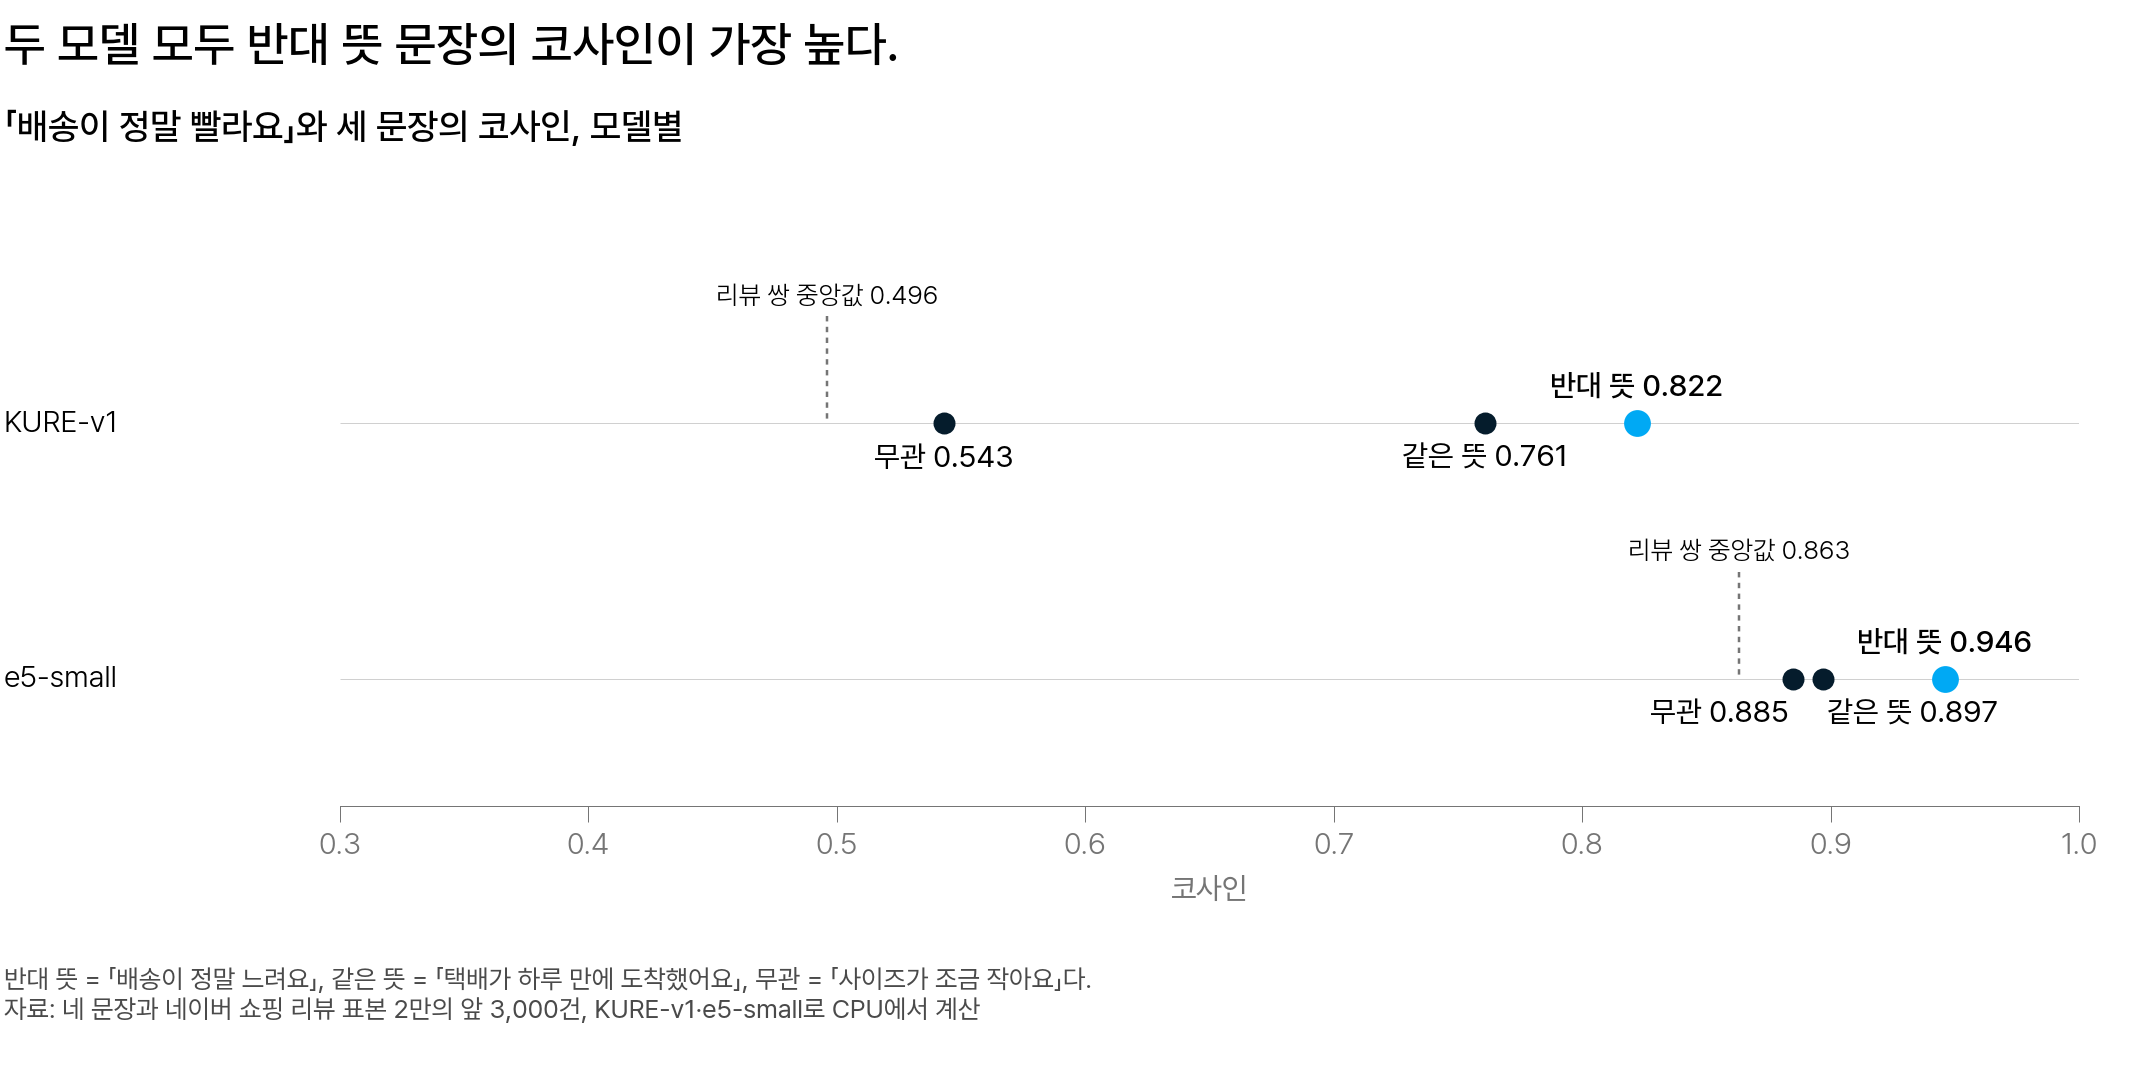

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 「배송이 정말 빨라요」와 각 문장의 코사인이다. 하늘색 점이 반대 뜻 문장 「배송이 정말 느려요」다. 회색 점선은 그 모델에서 리뷰 쌍 코사인의 중앙값이다</em></p>

**같은 이야기와 주제가 가까운 글은 무엇이 다른가요?**

같은 이야기는 같은 주제에 같은 주장인 글입니다. 반면 코사인이 높은 글은 **주제가 가까운 글**이고, 주장은 반대일 수 있습니다.

> 코사인은 주제가 같은지를 크게 반영하고, 주장이 같은지는 작게 반영합니다.

그래도 문장 임베딩은 문서-단어 행렬로는 못 찾던 글을 찾습니다. 같은 이야기인 「택배가 하루 만에 도착했어요」는 문서-단어 행렬에서 코사인이 0 이던 문장인데, 두 모델 모두 무관한 문장보다 높습니다.

다만 e5-small 은 무관한 문장 0.885 도 리뷰 쌍 중앙값 0.863 보다 높습니다. 같은 이야기 문장의 0.897 과도 0.012 차이뿐이라 두 글이 잘 구별되지 않습니다.

그래서 코사인으로 주제가 가까운 글을 고른 뒤, 같은 주장인지는 원문을 읽어 확인합니다.

### 같은 임계값도 모델마다 뜻이 다르다 [필수]

**한 모델에서 정한 임계값을 다른 모델에 써도 되나요?**

이번에는 리뷰 3,000건의 모든 쌍으로 넓힙니다. KURE-v1 로 쌍을 읽어 임계값을 0.90 으로 정했다고 하겠습니다. 모델만 e5-small 로 바꾸고 같은 0.90 을 쓰면 어떻게 될지 먼저 짐작해 봅니다.

> **[예측] KURE-v1 에서 정한 0.90 을 e5-small 에 그대로 쓰면, 리뷰 3,000건에서 그 이상인 쌍은 어떻게 될까요?**
>
> 1. 줄어든다
> 2. 비슷하다
> 3. 크게 늘어난다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

답은 셋째 보기입니다. 0.90 이상인 쌍은 KURE-v1 에서 110쌍, e5-small 에서 175,590쌍입니다. 175,590 ÷ 110 ≈ 1,596 이라 같은 0.90 으로 고른 쌍이 약 1,596배가 됩니다.

리뷰 3,000건의 모든 쌍 4,498,500개에서 임계값마다 그 이상인 쌍의 수를 구했습니다. 표의 비율은 임계값 이상인 쌍 가운데 한 리뷰가 1·2점, 다른 리뷰가 4·5점인 쌍의 비율입니다.

| 임계값 | KURE-v1 쌍 수 | 별점이 갈린 쌍 비율(%) | e5-small 쌍 수 | 별점이 갈린 쌍 비율(%) |
|---|---:|---:|---:|---:|
| 0.80 | 4,018 | 9.3 | 4,485,688 | 50.0 |
| 0.85 | 791 | 9.9 | 3,289,043 | 45.7 |
| 0.90 | 110 | 8.2 | 175,590 | 23.2 |
| 0.95 | 12 | 0.0 | 874 | 9.7 |

```text
0.90 이상 : KURE-v1 110쌍 · 8.2%  →  e5-small 175,590쌍 · 23.2%
0.80 이상 : e5-small 은 모든 쌍의 99.7% 를 고른다 → 비율이 모든 쌍의 50.0% 와 같다
```

같은 0.90 에서 별점이 갈린 쌍의 비율도 e5-small 이 3배 가까이 높습니다.

<details class="lms-extra"><summary>더 깊이 — 표본과 실행 환경에 따라 달라지는 쌍 수</summary>

「상위 k 와 임계값」에서 질의와 999건을 비교한 리뷰 1,000건으로 줄여도 같은 차이가 나타납니다. 이 1,000건의 모든 쌍 가운데 0.90 이상인 쌍은 KURE-v1 이 13쌍, e5-small 이 19,654쌍입니다.

| 임계값 | KURE-v1 쌍 수 | 별점이 갈린 쌍 비율(%) | e5-small 쌍 수 | 별점이 갈린 쌍 비율(%) |
|---|---:|---:|---:|---:|
| 0.90 | 13 | 0.0 | 19,654 | 24.4 |
| 0.95 | 2 | 0.0 | 88 | 8.0 |

실습은 GPU 가 있으면 KURE-v1, 없으면 e5-small 로 계산해 같은 문장에도 다른 코사인이 나옵니다. 또 코사인이 임계값 바로 근처인 쌍이 있어 같은 모델로도 기기에 따라 쌍 수가 몇 쌍 다르게 나올 수 있습니다.

</details>

**두 모델의 결과는 왜 이렇게 다른가요?**

두 모델의 코사인 분포가 다르기 때문입니다. 두 분포는 백분위수로 비교합니다.

**p 백분위수(p-th percentile)** 는 모든 쌍의 p% 가 그 값 이하인 코사인입니다. 예를 들어 KURE-v1 의 99백분위수 0.707 은 모든 쌍의 99% 가 0.707 이하라는 뜻입니다.

| 리뷰 3,000건 모든 쌍의 코사인 | KURE-v1 | e5-small |
|---|---:|---:|
| 1백분위수 | 0.341 | 0.811 |
| 50백분위수(중앙값) | 0.496 | 0.863 |
| 95백분위수 | 0.636 | 0.897 |
| 99백분위수 | 0.707 | 0.913 |
| 0.90 의 위치 | 99백분위수보다 위(10만 쌍에 약 2쌍) | 95백분위수 바로 위(100쌍에 약 4쌍) |

e5-small 의 1백분위수가 KURE-v1 의 99백분위수보다 큽니다. 그래서 두 모델의 가운데 98%(1～99백분위수) 범위가 겹치지 않습니다.

**코사인 0.90 은 가까운 쌍인가요?**

그 모델의 모든 쌍 가운데 0.90 이상이 얼마나 드문지로 판단합니다. 드물수록 가깝다는 근거가 강합니다. 그래서 0.90 은 KURE-v1 에서는 드물게 가까운 쌍이고, e5-small 에서는 흔한 값이라 근거가 약합니다.

e5-small 의 [모델 소개 문서](https://huggingface.co/intfloat/multilingual-e5-small)도 코사인이 0.7～1.0 에 모인다며 절댓값보다 순서가 중요하다고 설명합니다. 그래서 순서만 쓰는 상위 k 는 모델이 바뀌어도 덜 달라지고, 값을 쓰는 임계값은 모델마다 다시 정합니다.

> 임계값은 그 모델의 코사인 분포 안에서만 뜻이 있습니다.

**그러면 인코더는 무엇으로 고르나요?**

두 인코더는 사전학습 모델이라, 분석가는 아래 항목을 보고 하나를 골라 호출하기만 합니다.

| | KURE-v1 | multilingual-e5-small |
|---|---|---|
| 학습한 글 | 다국어 모델 BAAI/bge-m3 를 한국어로 더 학습 | 여러 언어를 함께 학습 |
| 라이선스 | MIT | MIT |
| 입력 상한 | 8,192토큰 | 512토큰 |
| 항공 민원 12,232건을 벡터로 바꾼 CPU 시간 | 180.7초 | 19.9초 |
| 이럴 때 쓴다 | GPU 로 한국어 글을 계산할 때 | CPU 에서 바로 계산할 때 |

MIT 는 저작권 표시만 남기면 회사에서도 자유롭게 쓸 수 있는 라이선스입니다. KURE-v1 에서는 같은 이야기 문장의 코사인이 리뷰 쌍 중앙값보다 뚜렷이 높습니다(0.761 대 0.496). 하지만 CPU 에서 약 9배 느립니다. 그래서 GPU 가 없으면 e5-small 을 쓰고, 임계값은 고른 모델에서 다시 정합니다.

<details class="lms-extra"><summary>자세히 — 처리 시간을 측정한 조건</summary>

같은 조건에서 KURE-v1 은 $180.7 \div 19.9 \approx 9$ 배 걸렸습니다. 이 시간은 노트북 컴퓨터 한 대(M1 Pro)의 CPU 6스레드에서 측정한 값입니다. 초는 기기마다 다르므로 두 모델의 비율을 봅니다.

</details>

> **[문제] 리뷰 두 개의 문장 임베딩 코사인이 0.9 이상이면 두 리뷰는 같은 뜻이다.**
>
> 1. O (맞다)
> 2. X (틀리다)

### 정밀도와 임계값 [필수]

**임계값 이상인 쌍은 실제로 어떤 글인가요?**

코사인이 가장 높은 쌍은 대개 같은 이야기입니다. 아래는 KURE-v1 에서 리뷰 3,000건 가운데 코사인이 가장 높은 2쌍(0.979 · 0.975)입니다. 표현만 다르고 별점도 같습니다.

| 리뷰 1 | 리뷰 2 | 별점 |
|---|---|---|
| 배송도 빨랐고 저렴하게 잘샀네여 | 저렴히 잘샀고 배송 빨랐습니다 | 둘 다 5점 |
| 배송이 좀 늦습니다. | 배송이 조금 늦어요 | 둘 다 2점 |

같은 모델에서도 0.95 이상에서 0.90 이상으로 넓히면 별점이 갈린 쌍의 비율이 커집니다.

```text
별점이 갈린 쌍 비율, 0.95 이상 → 0.90 이상
KURE-v1 : 0.0% → 8.2%
e5-small : 9.7% → 23.2%
```

e5-small 에서 0.90 바로 위인 쌍을 하나 읽어 봅니다. 175,590쌍을 모두 읽을 수는 없어서, 표본의 첫 리뷰(별점 1점)와 나머지 2,999건이 이루는 쌍만 봅니다. 아래는 첫 리뷰와 코사인이 0.900 이고 별점이 갈린 리뷰입니다.

> 재구매 오랫동안 잘 썼는데 이번에 사고 … 열흘동안 배송도 안해주고 전화도 안받고 …

> 완전 사고싶었던걸 여기에서 구매할수 있어서 너무나 기분이 좋아요. 감사합니다. 잘 신을께요.

앞 리뷰는 배송 불만이고 뒤 리뷰는 구매 만족이라 같은 이야기가 아닙니다. 이런 쌍은 0.90 바로 위에 몰려 있습니다.

```text
첫 리뷰와 0.90 이상이면서 별점이 갈린 리뷰 64건
↓ 그 가운데 코사인이 0.900～0.905 인 리뷰
32건(절반)
↓ 임계값을 0.005 높여 0.905 로 하면
이 32건이 빠진다
```

그래서 임계값을 정할 때는 그 값 바로 위와 아래의 쌍을 읽습니다.

**쌍은 어떤 차례로 읽나요?**

임계값은 쓰는 모델에서 사람이 쌍을 읽고 확인한 결과로 정합니다.

```text
판단 기준 한 문장을 먼저 정한다
(예: 같은 주제에 같은 주장이면 같은 이야기)
↓
코사인을 구간 몇 개로 나눈다(임계값 후보의 위와 아래 모두)
↓
구간마다 쌍을 무작위로 몇 개씩 고른다
↓
쌍마다 두 글을 읽고 같은 이야기인지 기록한다
↓
구간마다 같은 이야기인 쌍의 비율을 구한다
```

무작위로 고르는 이유는 코사인이 높은 쌍만 읽으면 같은 이야기인 쌍의 비율이 실제보다 높게 나오기 때문입니다.

**정밀도는 무엇인가요?**

**정밀도(precision)** 는 한 구간에서 읽은 쌍 가운데 같은 이야기로 확인한 쌍의 비율입니다. 위 흐름의 마지막 단계에서 구하는 값입니다.

$$
p = \frac{r}{n}
$$

- $p$: 그 구간의 정밀도
- $r$: 같은 이야기로 확인한 쌍의 수
- $n$: 그 구간에서 읽은 쌍의 수

정밀도의 기준을 80% 로 미리 정하고 두 구간에서 10쌍씩 읽었다고 하겠습니다.

| 코사인 구간 | 읽은 쌍 $n$ | 같은 이야기 $r$ | 정밀도 $p$ | 기준 80% |
|---|---:|---:|---:|---|
| 0.90～0.92 | 10 | 6 | 6 ÷ 10 = 60% | 못 미침 |
| 0.92～0.94 | 10 | 9 | 9 ÷ 10 = 90% | 넘음 |

기준을 넘는 구간의 아래 끝 0.92 가 임계값 후보입니다.

**10쌍만 읽고 임계값을 정해도 될까요?**

10쌍으로 구한 90% 는 추정값이라, 다른 10쌍을 읽으면 달라집니다. **표준오차**는 추정값이 표본에 따라 달라지는 정도이고, 읽은 쌍이 적을수록 큽니다.

그래서 참 정밀도의 범위도 구합니다. 참 정밀도는 그 구간의 쌍을 모두 읽었다면 나왔을 정밀도입니다. **95% 신뢰구간** 은 다른 쌍을 읽어 여러 번 구하면 그 가운데 약 95% 가 참 정밀도를 포함하는 범위입니다. 계산은 통계적 검정과 인과추론 과목에서 A/B 전환율의 신뢰구간에 쓴 Wilson 방법으로 합니다.

| 읽은 쌍 $n$ | 같은 이야기 $r$ | 정밀도 | 95% 신뢰구간 |
|---:|---:|---:|---|
| 10 | 9 | 90% | 약 60%～98% |
| 20 | 18 | 90% | 약 70%～97% |
| 40 | 36 | 90% | 약 77%～96% |
| 100 | 90 | 90% | 약 83%～94% |

읽은 쌍이 많을수록 구간이 좁아져, 100쌍에서 처음으로 아래 끝이 80% 를 넘습니다.

> 신뢰구간의 아래 끝이 기준을 넘으면, 참 정밀도도 기준을 넘는다고 볼 근거가 됩니다.

따라서 10쌍만 읽고는 0.92 를 임계값으로 확정하지 않습니다. 아래 끝이 80% 를 넘을 만큼 그 구간의 쌍을 더 읽습니다. 별점이 갈린 비율은 단서일 뿐이라, 쌍을 읽어 정밀도를 구하는 이 절차를 대신하지 못합니다.

<div class="lms-summary">

**정리**

코사인이 높으면 주제가 가깝다는 것까지만 말할 수 있습니다. 같은 0.90 도 모델에 따라 고르는 쌍의 수가 약 1,596배 다릅니다. 그래서 코사인 0.9 가 같은 이야기인지는 쓰는 모델에서 사람이 읽은 쌍으로만 답할 수 있습니다.

**할 일**

- 쓰는 모델로 구간마다 쌍을 무작위로 골라 읽고, 신뢰구간의 아래 끝이 기준을 넘는 구간에서 임계값을 정합니다
- 같은 주장인지는 원문을 읽어 확인합니다. 별점은 단서입니다
- 인코더는 라이선스, 한국어 학습, 입력 상한, 처리 시간으로 고릅니다

다른 모델에서 정한 임계값은 옮겨 쓰지 않습니다.

</div>

> **[문제] 다른 모델로 옮긴 임계값 0.90**
>
> 전임 담당자가 KURE-v1 의 코사인이 높은 리뷰 쌍을 읽어 보고 「코사인 0.90 이상이면 같은 이야기」로 정했습니다. 모델만 e5-small 로 바꾸고 0.90 을 그대로 쓰면 리뷰 3,000건에서 무엇이 달라지는지 수로 적고, 무엇을 다시 해야 하는지 한 문장으로 적어 보세요.

## 5. 항공 민원과 소비자원 표준답변

검색 시스템을 만들지 않는 분석가는 최근접 이웃 검색으로 어떤 질문에 답할까요?

### 최근접 이웃 검색으로 답하는 세 가지 분석 질문 [필수]

최근접 이웃 검색으로 질의와 코사인이 큰 글을 찾으면, 키워드로는 찾을 수 없는 글까지 건수에 포함할 수 있습니다. 답할 수 있는 분석 질문은 3가지입니다.

| 분석 질문 | 최근접 이웃 검색으로 하는 일 | 사람이 확인할 것 |
|---|---|---|
| 키워드로 찾지 못한 같은 이야기는 얼마나 되는가 | 질의와 코사인이 임계값 이상인 글 가운데 키워드가 없는 글의 수를 구한다(상위 k 는 읽을 글을 고를 때만 쓴다) | 키워드 없는 글이 정말 같은 이야기인지 |
| 거의 같은 글이 얼마나 함께 있는가 | 코사인이 임계값 이상인 쌍을 찾는다 | 임계값 위와 아래 구간에서 무작위로 읽은 정밀도 |
| 이 민원에 쓸 표준답변이 있는가 | 민원마다 가장 가까운 표준답변과 그 코사인을 구한다 | 구간마다 쌍을 읽어 정한 임계값 |

예를 들어 「환급」이라고 쓴 민원은 「환불」 민원과 같은 이야기지만, 「환불」이 있는 민원만 집계하면 빠집니다.

**거의 같은 글은 무엇이고 왜 찾나요?**

**거의 같은 글**은 몇 글자만 다르고 내용이 같은 글입니다. 앞에서 읽은 「배송이 좀 늦습니다.」와 「배송이 조금 늦어요」가 그 예입니다.

같은 글이 여러 번 있으면, 그 글에 나온 단어의 문서 비율이 실제보다 커집니다. 그래서 정확히 같은 글은 코사인 없이 문자열 비교로 찾고, 거의 같은 글은 코사인과 사람이 확인한 임계값으로 찾습니다.

<details class="lms-extra"><summary>더 깊이 — 모아 온 글의 지표 정의 항목</summary>

예를 들어 쇼핑 리뷰 20만 건에는 앞에 나온 리뷰와 본문이 정확히 같은 리뷰가 92건 있습니다. 본문이 같은 리뷰를 모두 합하면 184건입니다.

리뷰나 게시글을 웹에서 모아 왔다면 검색어, 거른 광고 글의 수, 거의 같은 글을 집계한 방법을 지표 정의에 남깁니다. 이 3가지가 모두 비율의 분모(전체 글 수)를 바꾸기 때문입니다.

</details>

다만 글이 거의 같아도 다른 사람이 같은 일을 겪어 쓴 글일 수 있습니다. 그래서 처리는 자료마다 다릅니다.

| 자료 | 거의 같은 글의 처리 |
|---|---|
| 웹에서 모아 온 리뷰 · 게시글 | 수집할 때 같은 글이 겹쳐 저장되는 일이 있어 한 건으로 합친다 |
| 민원 | 다른 사람이 낸 글일 수 있어 빼지 않고, 거의 같은 글의 비율을 따로 구한다 |

> 세 질문 모두 건수는 코사인으로 구하지만 그 수가 맞는지는 임계값 근처의 원문을 읽어야 압니다.

### 항공 민원에 대응하는 표준답변이 있는가 [필수]

**어떤 두 자료를 비교하나요?**

하나는 공정거래위원회 2020년 소비자 민원 파일 1 입니다. 시험 입력과 빈 제목을 뺀 민원 499,844건입니다. 아래는 그 가운데 항공여객운송서비스 품목의 민원 3건입니다.

| 사건번호 | 접수일자 | 품목명 | 사건제목 |
|---|---|---|---|
| 2020-0000005 | 2020-01-01 | 항공여객운송서비스 | 마일리지 사용 제한 |
| 2020-0000308 | 2020-01-02 | 항공여객운송서비스 | 항공권 예약 취소 처리 요구 |
| 2020-0000446 | 2020-01-02 | 항공여객운송서비스 | 항공권 취소시 수수료 과다 청구 불만 |

다른 하나는 한국소비자원의 「소비자상담 표준답변」입니다. 상담원이 자주 받는 질문에 쓰는 답변을 품목별로 모은 표입니다. 공공데이터포털(data.go.kr 15144809)에서 이용 조건 없이 받습니다.

표준답변은 1,332행 × 5열이고 품목은 56종입니다. 아래는 그 가운데 항공 품목의 표준답변 하나입니다.

| 열 | 값 |
|---|---|
| 번호 | 1234 |
| 품목명 | 항공여객운송서비스 |
| 구분 | 계약불이행_일방적인 항공편 취소 |
| 질문 | … 귀국 시 비엔나→인천 편도 항공편이 취소되었습니다. 구제 방법이 있나요? |
| 답변 | 사업자가 … 불가피하게 항공 운행을 하지 못한 사실을 증명하지 못할 경우에는 손해배상을 요구할 수 있습니다. … (이하 생략) |

먼저 품목마다 민원 수와 표준답변 수를 나란히 계산합니다. 민원이 많은 품목에는 표준답변도 많을까요?

민원이 많다고 표준답변도 많은 것은 아닙니다. 국외여행 민원은 13,012건인데, 품목 이름이 같은 표준답변은 하나도 없습니다.

아래 그림에서 가로축은 품목의 민원 수(10배마다 같은 간격), 세로축은 표준답변 수입니다. 하늘색 점이 국외여행입니다. 이름이 적힌 나머지 남색 점 3개는 민원이 1만 건을 넘고 표준답변이 15～30개입니다.

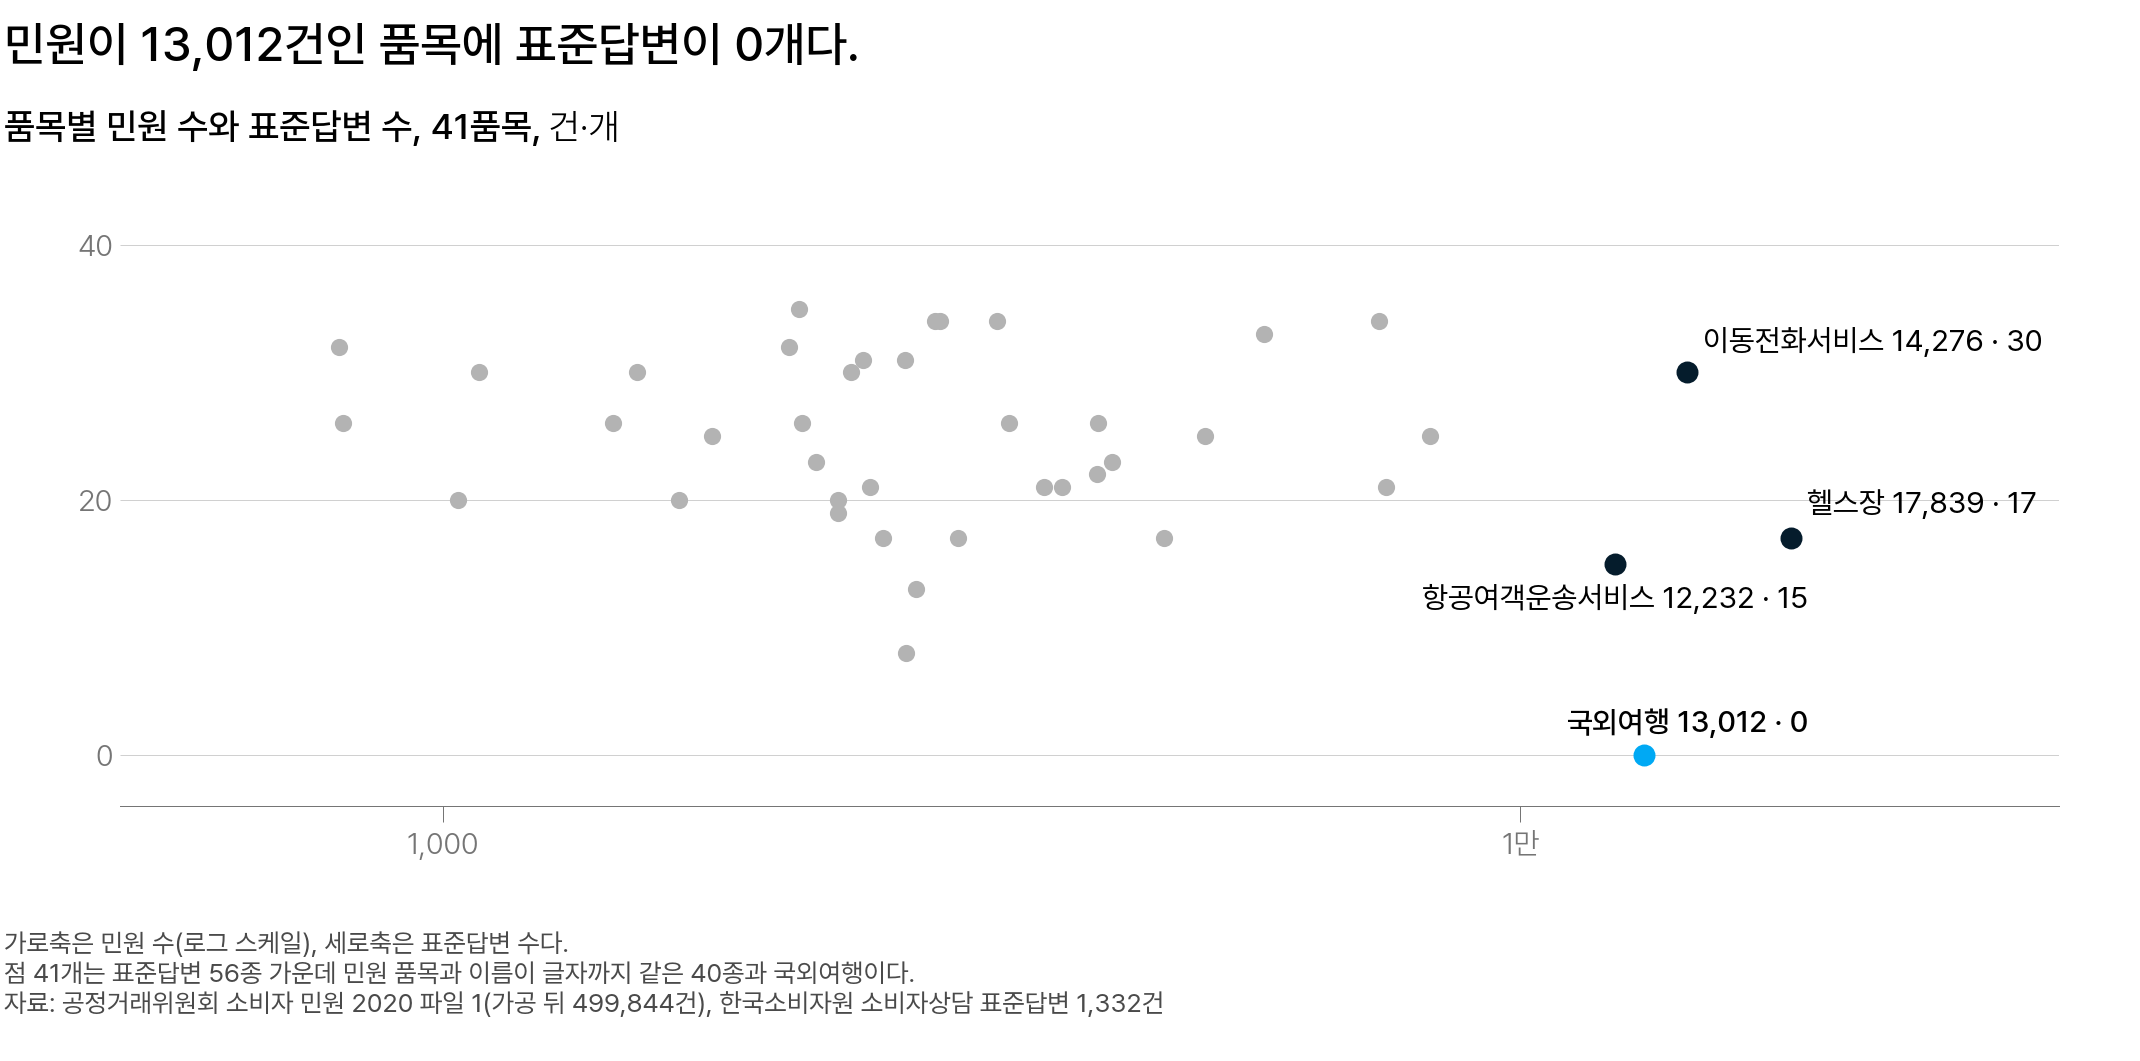

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 하늘색 점이 국외여행이다. 남색 점 3개는 민원이 1만 건 넘는 품목이다</em></p>

**이름이 같은 답이 없으면 대응하는 답도 없나요?**

그렇게 말할 수 없습니다. 이유는 2가지입니다.

- 같은 품목도 두 자료에서 이름이 다를 수 있습니다. 표준답변 품목 56종 가운데 16종은 민원 품목과 이름이 정확히 같지 않습니다. 예를 들어 표준답변의 「정수기대여」 43개는 민원의 「정수기대여(렌트)」 10,847건과 같은 품목입니다.
- 국외여행에 해당하는 이름은 56종 가운데 없습니다. 그래도 국외여행 민원에 맞는 답이 항공 같은 다른 품목에 있을 수 있습니다.

> 이름이 같은 답이 0개라는 것과 대응하는 답이 없다는 것은 다릅니다.

**대응하는 답은 어떻게 찾나요?**

민원 한 건마다 가장 가까운 표준답변을 찾습니다. 민원 $i$ 의 **가장 가까운 답의 코사인** $m_i$ 는 민원 $i$ 와 표준답변 1,332개 각각의 코사인 가운데 가장 큰 값입니다.

$$
m_i = \max_{j = 1,\dots,1332} \cos(\mathbf{c}_i, \mathbf{a}_j)
$$

- $m_i$: 민원 $i$ 의 가장 가까운 답의 코사인
- $i$: 항공 민원 번호(1～12,232)
- $j$: 표준답변 번호(1～1,332)
- $\mathbf{c}_i$: 민원 $i$ 의 사건제목 문장 임베딩
- $\mathbf{a}_j$: 표준답변 $j$ 의 「질문」 열 문장 임베딩

「질문」 열을 쓰는 이유는 소비자가 쓴 짧은 문제 설명끼리 비교하기 위해서입니다. 「답변」 열은 글자 수 중앙값이 487자인 긴 설명입니다.

예를 들어 표준답변이 3개뿐이고 민원 하나와 세 답변의 코사인이 0.61, 0.66, 0.59 라고 하겠습니다.

$$
m_i = \max(0.61,\ 0.66,\ 0.59) = 0.66
$$

이 민원의 가장 가까운 답은 둘째 답변입니다. 실제로는 민원 12,232건 × 답변 1,332개의 행렬곱 한 번으로 모든 코사인을 얻고, 민원마다 가장 큰 값을 고릅니다.

이 방법은 항공 민원으로 먼저 확인합니다. 항공은 이름이 같은 표준답변이 15개라, 가장 가까운 답이 그 가운데 하나인지 대조할 수 있습니다.

**같은 민원에서 두 모델의 코사인은 얼마나 다른가요?**

아래 그림에서 가로축은 항공 민원 12,232건의 $m_i$ 이고 위 줄은 KURE-v1, 아래 줄은 e5-small 의 백분위수입니다.

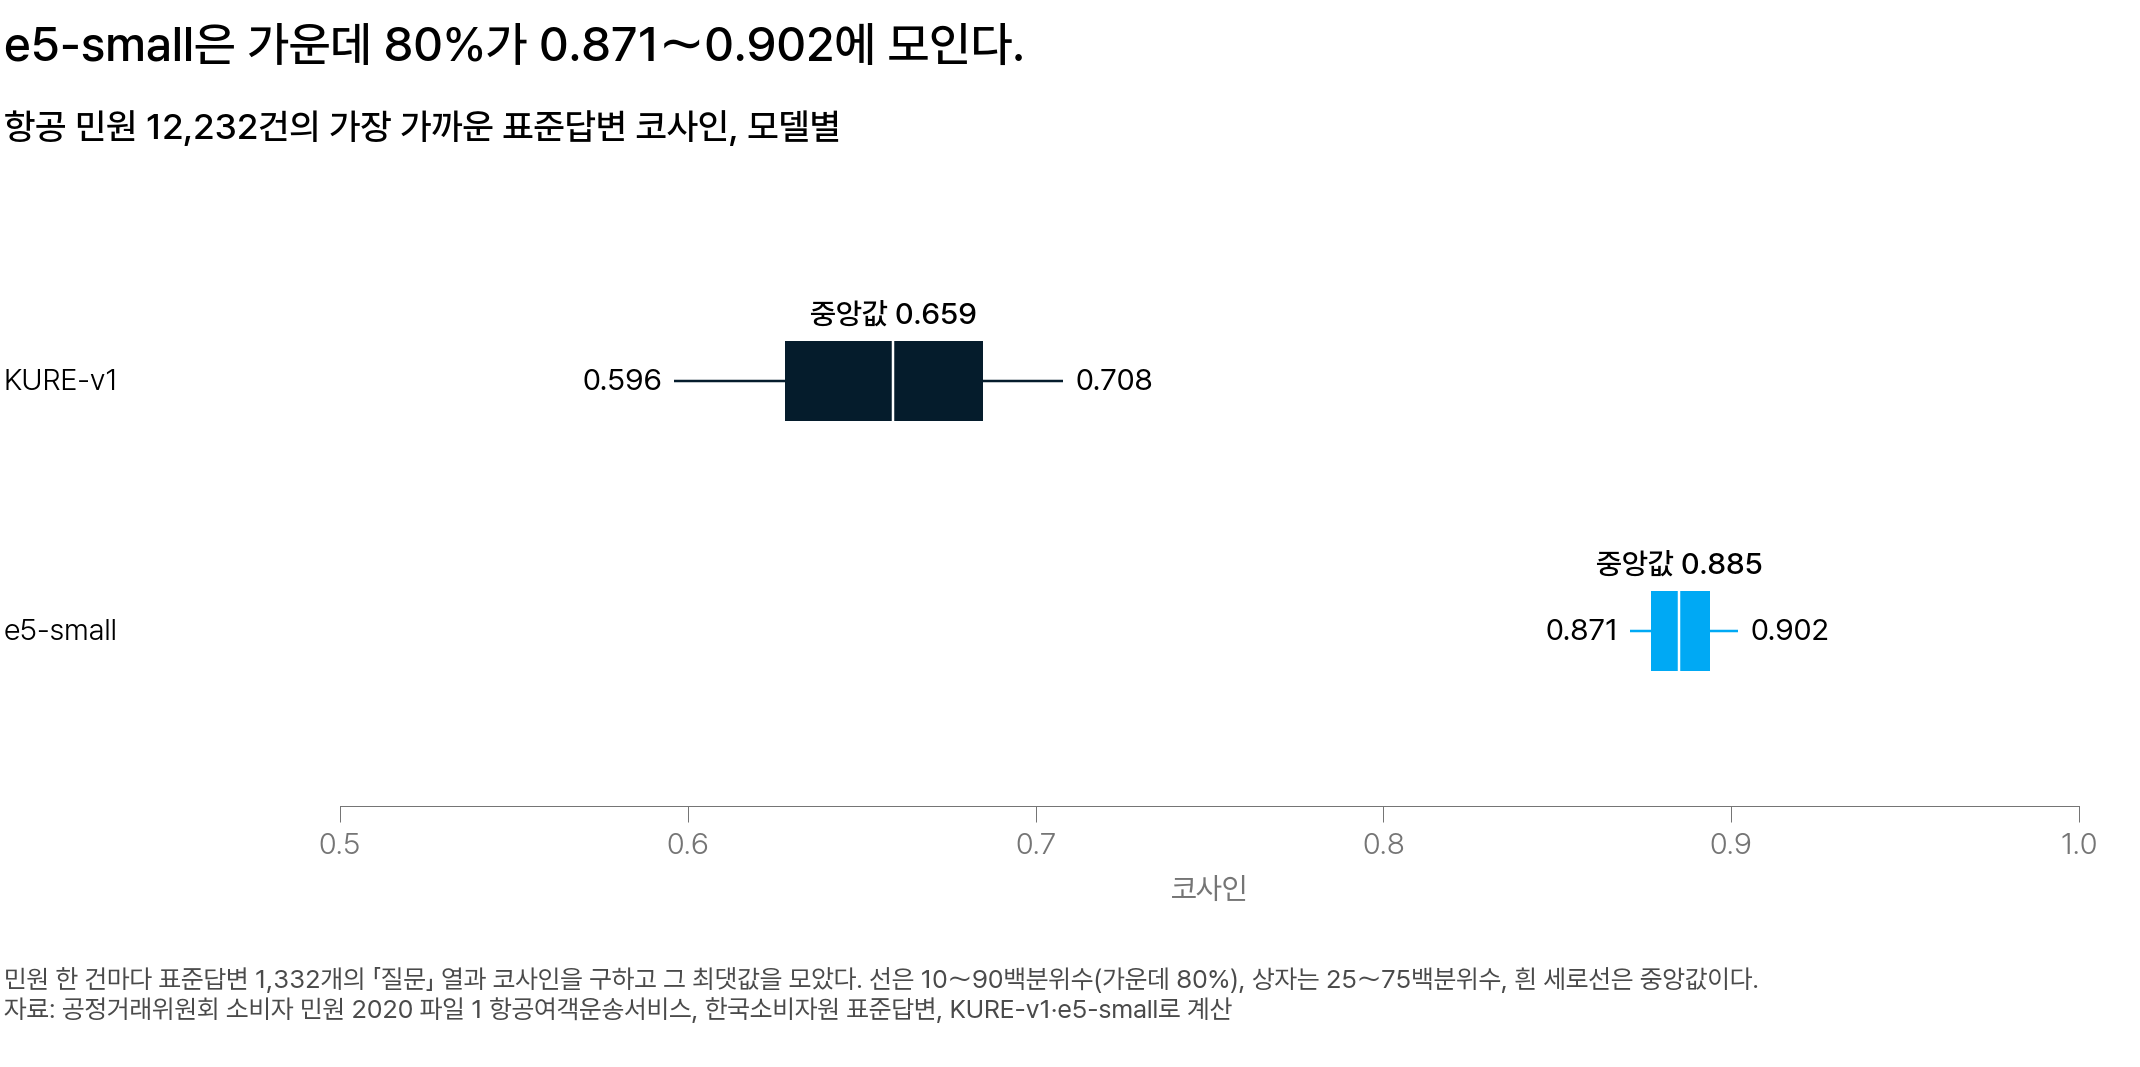

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로는 가장 가까운 답의 코사인, 위아래 줄이 두 모델이다. 선은 10～90백분위수, 상자는 25～75백분위수, 흰 세로선은 중앙값이다</em></p>

같은 민원과 같은 답변인데 두 모델의 $m_i$ 는 크게 다릅니다. 「0.8 이상이면 대응한다」는 기준을 두 모델에 같게 쓰면 대응 없는 민원 수가 크게 달라집니다.

| 항공 민원 12,232건 | KURE-v1 | e5-small |
|---|---|---|
| $m_i$ 의 10～90백분위수 | 0.596～0.708 | 0.871～0.902 |
| 대응 없음($m_i$ 가 0.8 미만) | 90% 이상, 12,232 × 0.9 ≈ 11,009건 이상 | 10% 이하, 12,232 × 0.1 ≈ 1,223건 이하 |

같은 기준 · 같은 민원인데 대응 없음이 9배 이상 차이 납니다. 또 e5-small 은 가운데 80% 가 0.871～0.902 에 모여 있습니다. 범위가 0.031 이라 임계값을 0.01 만 바꿔도 대응 없는 민원의 수가 크게 바뀝니다.

> 「0.8 이상이면 대응한다」 같은 기준은 어느 모델의 코사인인지 모르면 뜻이 없습니다.

**가장 가까운 답은 맞는 답인가요?**

KURE-v1 에서 항공 민원의 76.1%(약 4건 중 3건)는 가장 가까운 답도 항공 품목입니다. 그 답이 민원에 맞는지 실제 쌍 하나로 확인합니다.

| 항공 민원 | KURE-v1 로 가장 가까운 표준답변 | $m_i$ |
|---|---|---:|
| 출국 항공기 결항에 입국 항공권 해지에 취소수수료 청구 부당 | 항공 품목 「청약철회_미성년자 계약」(번호 1230) | 0.618 |

결항 민원인데 미성년자 계약의 청약철회 답이 나온 것입니다. 항공 표준답변에 있는 「계약불이행_일방적인 항공편 취소」는 가장 가까운 답이 아니었습니다.

이런 답은 한 번으로 그치지 않습니다. KURE-v1 코사인 구간 5개에서 8쌍씩, 모두 40쌍을 읽으면 그 가운데 10쌍(4분의 1)의 가장 가까운 답이 이 1230번입니다. 구간마다 8쌍씩 읽은 것은 틀린 답이 어느 구간에 몰리는지 보려는 첫 확인입니다. 임계값을 확정하려면 그 구간의 쌍을 더 읽습니다.

대응하는 답이 있는지는 쌍을 읽어야 압니다.

<div class="lms-summary">

**정리**

분석가는 최근접 이웃 검색으로 키워드로 찾지 못한 같은 이야기, 거의 같은 글, 민원에 대응하는 표준답변을 찾습니다. 다만 이름이 같은 표준답변이 0개여도 대응하는 답이 없다고 할 수 없고, 가장 가까운 답이 맞는 답이라는 보장도 없습니다.

**할 일**

- 민원 사건제목과 표준답변 「질문」 열을 같은 문장 인코더로 바꿔 민원마다 가장 가까운 답의 코사인을 구합니다
- 쓰는 모델에서 코사인 구간마다 쌍을 읽어 정한 임계값으로, 대응하는 답이 없는 민원을 집계합니다

항공 민원에서는 품목이 같아도 민원에 맞지 않는 답(번호 1230)이 가장 가까운 답으로 여러 번 나왔습니다.

</div>

> **[문제] 표준답변 0개는 대응할 답이 없다는 뜻인가**
>
> 국외여행 민원은 13,012건인데 국외여행 품목의 표준답변은 0개입니다. 이 사실로 「국외여행 민원은 소비자원 표준답변으로 전혀 대응할 수 없다」고 결론 내려도 될까요? 그렇게 판단하기 전에 무엇을 확인해야 하는지 적어 보세요.

## 6. 정리와 팀 라운드

코사인으로 구한 건수는 무엇이 있어야 믿을 수 있을까요?

### 코사인으로 구한 건수에 필요한 세 가지 [필수]

코사인으로 구한 건수는 임계값 이상인 리뷰 쌍의 수, 가까운 표준답변이 없는 민원 수 같은 것입니다. 이런 건수는 아래 세 가지가 있어야 뜻이 정해집니다.

| 항목 | 없으면 생기는 일 | 이 과정의 예 |
|---|---|---|
| 모델 이름과 버전 | 같은 임계값으로 고른 쌍의 수를 비교할 수 없다 | 0.90 이상인 쌍이 KURE-v1 은 110쌍, e5-small 은 175,590쌍 |
| 임계값과 그 근거 | 그 임계값을 믿을지 판단할 수 없다 | 구간마다 무작위로 골라 읽은 쌍의 수 · 정밀도 · 신뢰구간 |
| 사람이 읽은 원문 | 정밀도는 수로만 남아, 받는 사람이 「같은 이야기」의 기준이 자기 목적에 맞는지 직접 볼 수 없다 | e5-small 코사인 0.900 인 1점 · 5점 리뷰 쌍은 배송 불만과 구매 만족 |

모델의 버전은 Hugging Face 저장소의 revision 입니다. revision 은 모델 파일이 바뀔 때마다 새로 생기는 기록의 이름이라, revision 까지 같아야 같은 수를 다시 얻을 수 있습니다.

<details class="lms-extra"><summary>더 깊이 — 최근접 이웃 검색에서 시작하는 검색 증강 생성(RAG)</summary>

**검색 증강 생성(retrieval-augmented generation, RAG)** 은 찾은 문서를 LLM 의 입력에 더해 답을 만드는 구조입니다. RAG 의 첫 단계는 최근접 이웃 검색입니다.

분석가는 NotebookLM 같은 도구를 사용하는 쪽입니다. NotebookLM 은 사용자가 업로드한 문서를 근거로 질문에 답하는 구글의 AI 도구입니다. 문서를 나눠 저장하고 검색 품질을 관리하는 시스템 구축은 엔지니어가 맡습니다.

<img src="https://raw.githubusercontent.com/UKPLab/sentence-transformers/master/docs/img/InformationRetrieval.png" alt="질문이 Retrieval Bi-Encoder 로 문서 모음에서 후보를 찾고 Re-Ranker Cross-Encoder 가 순위를 매기는 흐름" width="560" height="165" />
<p align="center"><em>▲ 후보 검색과 재순위화의 두 단계. Retrieval Bi-Encoder 는 질문과 문서를 따로 벡터로 바꿔 가까운 후보를 먼저 찾는다. 이 과정의 문장 인코더와 같은 방식이다. Re-Ranker Cross-Encoder 는 그 후보만 질문과 한 번에 입력해 다시 순서를 매긴다 (출처: sentence-transformers 문서 Retrieve & Re-Rank, Apache-2.0)</em></p>

검색 시스템을 만드는 쪽에서 쓰는 **하이브리드 검색**은 키워드 검색과 임베딩 검색을 함께 쓰는 방법입니다. 찾은 문서의 순서를 다시 매기는 일은 **재순위화(reranking)** 입니다. 그림의 Re-Ranker 가 재순위화를 하는 모델입니다.

수백만 건이면 벡터를 저장하고 빨리 찾는 벡터 데이터베이스(vector database)를 씁니다. 이 과정의 수만 건은 행렬곱으로 충분합니다.

</details>

<div class="lms-summary">

**정리**

단어가 겹치지 않아도 주제가 가까운 글은 문장 임베딩의 코사인으로 찾습니다. 같은 이야기인지와 임계값은 쓰는 모델에서 사람이 확인한 쌍으로 정합니다.

**할 일**

- 다른 사람이 코사인으로 구한 건수를 받으면 모델 이름, 임계값의 근거, 임계값 바로 위와 아래의 원문을 먼저 확인합니다

코사인 몇 이상을 같은 이야기로 볼지는 모든 모델에 통하는 수 하나로 정할 수 없습니다.

</div>

### 팀 라운드: 코사인 0.85 로 지운 중복 문의 [필수]

아래 질문의 답은 수업에서 팀이 함께 정합니다. 지금은 자기 답과 근거만 적어 두면 됩니다.

각자 답과 확신도(1～5)를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거 세 문장을 나눠 토론한 뒤 팀이 답 하나로 모아 제출합니다.

> **[문제] 팀 라운드: 코사인 0.85 로 지운 중복 문의를 상담 인력의 근거로 쓸 것인가**
>
> 상담 운영팀이 「중복 문의가 많으니 상담 인력을 줄여도 된다」며 검토를 요청했습니다. 항공 민원 제목의 코사인이 0.85 이상인 쌍을 같은 문의로 보고 한 건만 남겼고, 그런 쌍 20개 가운데 18개가 같은 내용이었다고 합니다. 쓴 모델과 20쌍을 고른 방법은 알리지 않아, 분석팀이 같은 민원으로 수를 다시 구했습니다.
> 
> - **코사인 0.85 이상인 쌍의 비율(모든 쌍 가운데)** KURE-v1 1.02% · e5-small 88.63%
> - **읽은 쌍으로 구한 정밀도 90% 의 95% 신뢰구간(Wilson 방법)** 약 70%～97%
> - **제목이 정확히 같은 글이 가장 많은 「항공권 환불」 49건** 성별 · 연령대 · 지역 조합 41가지
> - **제목이 같아 지워지는 민원 1,304건 가운데** 성별 · 연령대 · 지역이 같은 앞 접수가 7일 안에 있는 민원 211건(16.2%)
> 
> 팀 안에서 의견이 3가지로 나뉘었습니다.
> 
> - **관점 A: 모델 이름과 임계값의 근거를 갖춘 수를 다시 요청한다.** 같은 0.85 라도 모델에 따라 고르는 쌍이 크게 다르다. 구간마다 무작위로 골라 읽은 정밀도와 신뢰구간을 받아, 중복을 뺀 민원 수부터 바로잡는다.
> - **관점 B: 이 수를 인력 결정에는 쓰지 않는다.** 상담은 사건마다 생기므로, 글이 겹치는 것과 같은 소비자가 같은 사건으로 다시 낸 것을 나눈다. 운영팀이 가진 접수자 정보로 중복 접수 건수를 따로 구한다.
> - **관점 C: 받아들인다.** 높은 임계값에서 배운 순서대로 사람이 쌍을 읽었고, 대부분 같은 내용이었다. 그러니 지운 민원 대부분이 중복이다.
> 
> 자기 입장 하나와 근거 세 문장, 다음에 확인할 일 하나, 그리고 확신도를 정해 오세요.